# 05 · Zero-shot LLM methods: Code2Tag and DesCode2Tag

This notebook reproduces the xCodeEval paper's only tag classifier: an LLM asked zero-shot for a
problem's tags, from its solution alone (Code2Tag) or from its statement, notes and solution
(DesCode2Tag). It asks `gpt-6-luna` instead of the paper's `gpt-3.5-turbo-0301`, once per
problem of the frozen split, in two output formats: the paper's free-text answer (`text`) and
OpenAI's structured output under a strict JSON schema (`json`). That makes four zero-shot
methods: `code2tag-text`, `code2tag-json`, `descode2tag-text` and `descode2tag-json`. They are
compared with the paper on its own metric, the all-tag macro F1, and on the 8 focus tags with
the TF-IDF baseline of notebook 04 (`tfidf`) and the label-prior floor (`label_prior`), with
their inference time and cost. Last, the MLflow UI shows every problem's predictions, method
by method (section 9).

**Contents**
1. The setup beside the paper
2. Answer health
3. Against the paper
4. Focus tags against TF-IDF and the label prior
5. Free text against structured output
6. Slices: release era, focus-tagged problems, self-identifying solutions
7. Where TF-IDF and the LLM disagree, on dev
8. Inference time and cost
9. Every problem in MLflow
10. Takeaways and next steps

**How it was built**
- **Fixed before the first request.** The prompts, the answer schema, the fields each prompt
  reads and the request settings live in `codeforces_tags/methods/zero_shot/`. They were
  approved before the first paid request and never edited after it
  ([ADR 0003](../docs/adr/0003-api-methods-are-fixed-reference-models.md)): every request's
  hash covers them, and `llm run` refuses an answers file under another hash. Nothing was
  tuned: a zero-shot method learns nothing from dev, so its dev predictions are as honest as
  out-of-fold ones.
- **Asked once, dev first.** `python -m codeforces_tags.llm run` asked every dev problem once,
  then every test problem once, under a cost cap, appending each answer to the method's
  committed `answers_dev.jsonl` and `answers_test.jsonl`. The test problems were asked only
  after the four dev answers files were committed and the comparison of `text` with `json` was
  concluded on dev (section 5), so nothing here is chosen on test.
- **From frozen files.** `llm score` froze each method's 0/1 predictions over the 37 tags, each
  problem's call (tokens, cost, latency) and a run record; `tracking latency` timed 50 dev
  problems one request at a time. This notebook reads those files, the answers files and the
  dataset's true tags. It sends no request, needs no API key, and imports neither mlflow nor
  openai.
- **Mirrored in MLflow.** `tracking datasets` and `tracking evaluate` log the same frozen
  predictions of the six methods, one trace per problem, to a local MLflow store. Section 9
  shows that store in screenshots of its UI, which `notebooks/figures/mlflow_ui.py` retakes;
  the notebook reads only their PNG files.
- **Two metrics.** The macro F1 over the 8 focus tags, the project's primary metric, compares
  the methods with `tfidf` and `label_prior`. The all-tag macro F1, over every tag with at
  least one problem in the part (37 on dev, 36 on test), compares them with the paper.
- **Intervals come from a group bootstrap**: 2,000 resamples of near-duplicate groups, 95%
  percentile intervals, as in notebook 04. Paired differences and the errors of section 7 are
  read on dev only; the test scores are reported side by side, each method on its own
  ([ADR 0001](../docs/adr/0001-model-selection-protocol.md)).

The way from a raw problem to its scores (source: `figures/zero_shot_pipeline.mmd`):

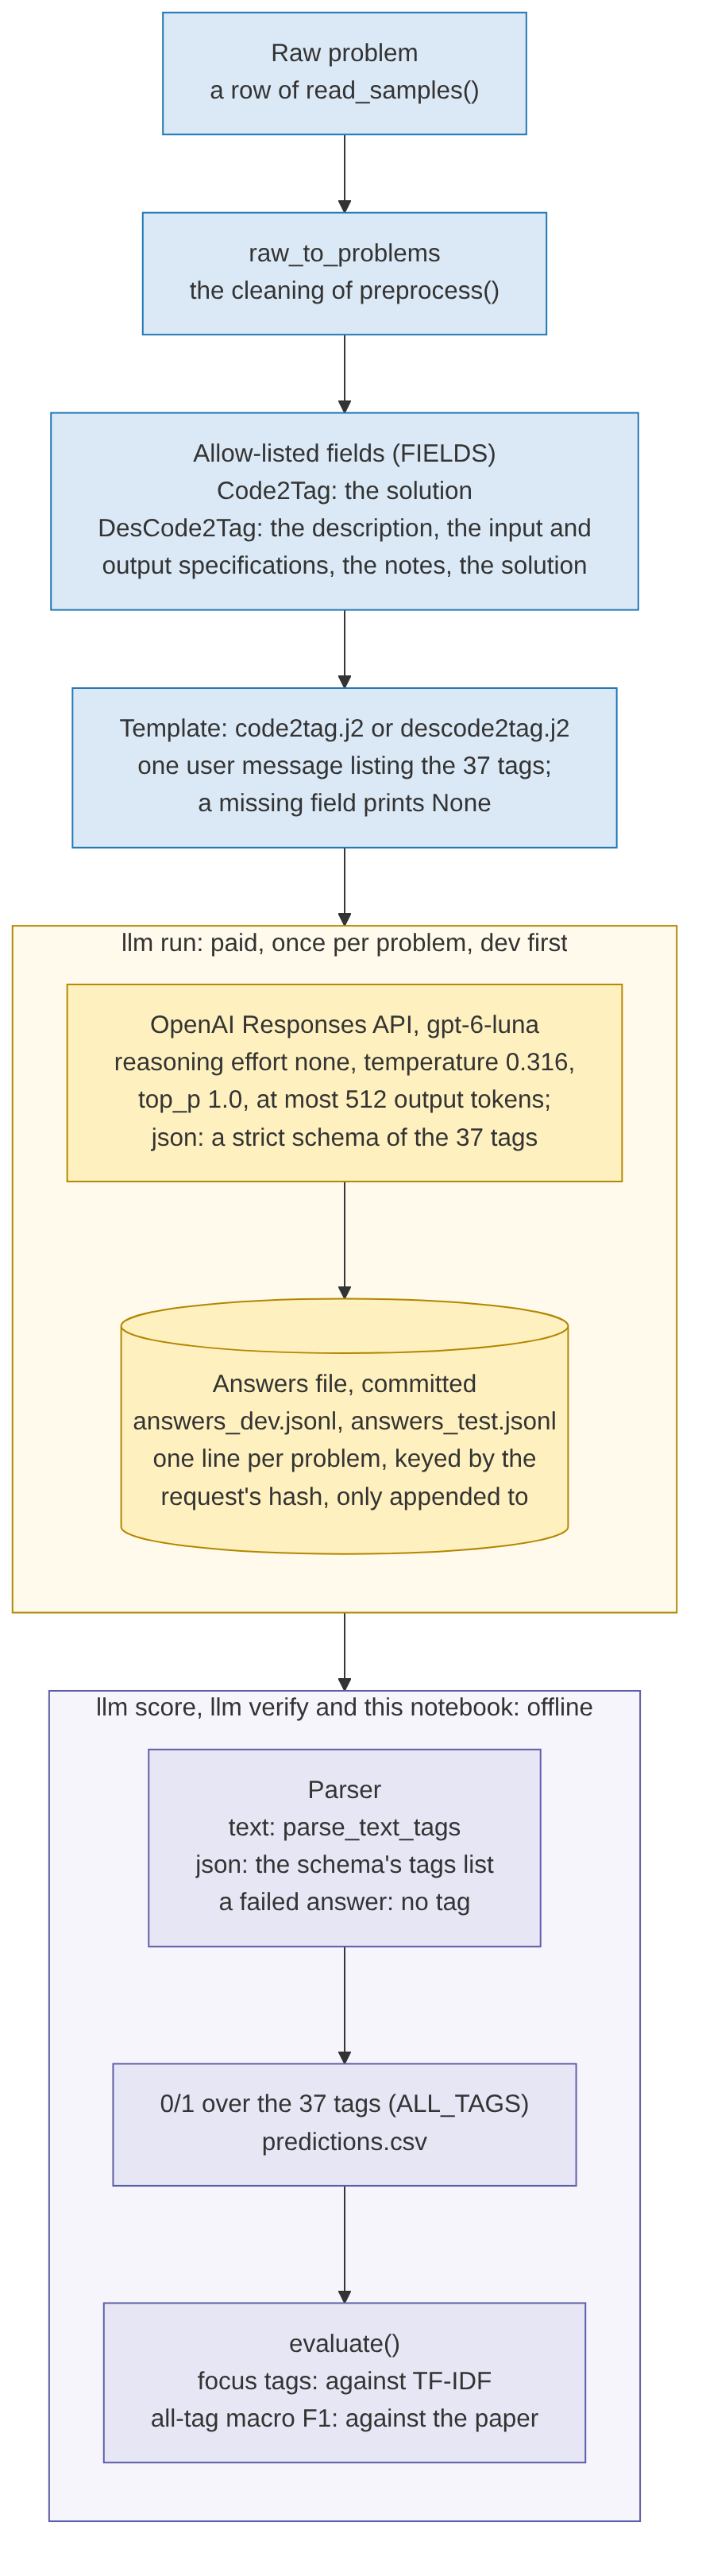

In [1]:
from IPython.display import Image

Image(filename="figures/zero_shot_pipeline.png", width=380)

**Setup.** The true tags come from the dataset and the frozen split; everything the methods
produced comes from their committed files. The cell fails unless, for each zero-shot method and
part, the answers file holds one answer per problem, its sha256 is the one the run record froze,
and its answers, parsed again (`encode_answers()`), give the frozen predictions exactly. Each
method's `recipe_sha256` is the tag that finds its run in MLflow, where `llm score` logged it.

In [2]:
import json
import sys
import textwrap

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from codeforces_tags.analysis.comparison import agreement, method_scores
from codeforces_tags.analysis.llm_methods import (
    all_tag_scores,
    answer_health,
    cost_per_thousand,
    disagreements,
    tags_per_answer,
)
from codeforces_tags.analysis.plotting import (
    plot_confusion_grid,
    plot_latency,
    plot_method_f1,
    plot_tag_confusion,
    setup_style,
)
from codeforces_tags.config import (
    ALL_TAGS,
    ERROR_EXCERPT_CHARS,
    FOCUS_TAGS,
    LATENCY_BUDGET_S,
    MLFLOW_SCREEN_COMPARE,
    MLFLOW_SCREEN_SAMPLE_ID,
    MLFLOW_SCREEN_TAG,
    MLFLOW_SCREENS_DIR,
    TFIDF_TEST_MACRO_F1,
)
from codeforces_tags.data.labels import focus_labels, multi_hot
from codeforces_tags.data.loading import read_samples
from codeforces_tags.evaluation.contamination import load_slice
from codeforces_tags.evaluation.predictions import (
    load_per_problem,
    load_predictions,
    load_run_record,
)
from codeforces_tags.evaluation.report import ALL_PROBLEMS, compare, evaluate
from codeforces_tags.evaluation.timing import latency_summary, load_latency
from codeforces_tags.llm.answers import encode_answers
from codeforces_tags.llm.prompts import field_values, prompt_snapshot
from codeforces_tags.llm.store import answers_file, read_answers
from codeforces_tags.methods import load_method, method_dir, model_dir
from codeforces_tags.methods.zero_shot.methods import llm_spec
from codeforces_tags.methods.zero_shot.settings import (
    FIELDS,
    METHOD_NAMES,
    PAPER_ALL_TAG_MACRO_F1,
    PROMPT_PATHS,
    PROMPT_VERSIONS,
    SETTINGS,
)
from codeforces_tags.preprocessing.pipeline import preprocess
from codeforces_tags.provenance import file_sha256
from codeforces_tags.splitting import PARTS, load_split, release_years, select_part

setup_style()
pd.set_option("display.max_colwidth", 110)

# The true tags come from the dataset and the frozen split; everything the methods produced
# (answers, predictions, calls, run records, timings) from their committed files.
raw = read_samples()
df = preprocess(raw)
split = load_split()
problems = {part: select_part(df, split, part) for part in PARTS}
focus = list(FOCUS_TAGS)
focus_truth = {part: focus_labels(problems[part]) for part in PARTS}
all_truth = {part: multi_hot(problems[part]["tags"], ALL_TAGS) for part in PARTS}
REFERENCES = ("label_prior", "tfidf")
COMPARED = (*REFERENCES, *METHOD_NAMES)
predictions = {name: load_predictions(method_dir(name)) for name in COMPARED}
latencies = {name: load_latency(method_dir(name)) for name in COMPARED}
records = {name: load_run_record(method_dir(name)) for name in METHOD_NAMES}
per_problem = {name: load_per_problem(method_dir(name)) for name in METHOD_NAMES}
answers = {
    name: {part: read_answers(answers_file(name, part)) for part in PARTS} for name in METHOD_NAMES
}
contamination = load_slice()

for name in COMPARED:
    for part in PARTS:
        assert predictions[name].loc[part].index.equals(problems[part].index), f"{name}, {part}"
for name in METHOD_NAMES:
    entries = records[name].method_entries
    for part in PARTS:
        assert len(answers[name][part]) == len(problems[part]), f"{name}, {part}: answer count"
        sha256 = file_sha256(answers_file(name, part))
        assert entries["answers_sha256"][part] == sha256, f"{name}, {part}: answers changed"
        output_format = entries["llm_settings"]["output_format"]
        encoded = encode_answers(answers[name][part], problems[part].index, output_format)
        assert predictions[name].loc[part].equals(encoded), f"{name}, {part}: not its answers"
assert contamination["part"].value_counts().to_dict() == {"dev": 50, "test": 16}
print(
    f"dev set: {len(problems['dev']):,} problems, test set: {len(problems['test']):,}; "
    f"self-identifying solutions: {len(contamination)}"
)
pd.DataFrame(
    {
        name: {
            "prompt": records[name].prompts[0],
            "dev answers": len(answers[name]["dev"]),
            "test answers": len(answers[name]["test"]),
            "recipe_sha256": records[name].recipe_sha256,
        }
        for name in METHOD_NAMES
    }
).T

dev set: 3,988 problems, test set: 994; self-identifying solutions: 66


,prompt,dev answers,test answers,recipe_sha256
code2tag-text,prompts:/code2tag/1,3988,994,6706d1c84967743ff9afa158bbc75acc5c7cea023fa413b0ff2a59959d1e019f
code2tag-json,prompts:/code2tag/2,3988,994,ba9ac4f376b2bed9a07f5958635ec027a0d28ff808fc7a2ed5e21ddf4965ffd1
descode2tag-text,prompts:/descode2tag/1,3988,994,8386139f11750b3e22529445aa7597aab4bea75fdd0c79bf94b1b68c4f382312
descode2tag-json,prompts:/descode2tag/2,3988,994,ab2e1bf3792022a0ab2232b010d3a9810c645ad1b067447a9562d9363a21b696


## 1. The setup beside the paper

The paper gives its settings in a few lines and never shows its prompts, and the official
repository has no tag-classification code
([paper notes](../docs/xcodeeval-paper-notes.md), section 5). What it states, and what this
notebook ran:

| | The paper (Table 3, Python) | Here |
|---|---|---|
| Model | `gpt-3.5-turbo-0301`, through ChatCompletion | `gpt-6-luna`, through the Responses API, at reasoning effort `none` |
| Prompting | zero-shot, direct, n = 1 | zero-shot: one user message, no system prompt, no example, no reasoning asked for |
| Sampling | temperature "0.325"; the authors' code draws 0.3158, a point of `np.linspace(0, 2, 20)` | temperature 0.3157894736842105, top_p 1.0, at most 512 output tokens |
| Inputs | Code2Tag: the solution; DesCode2Tag: the description and the solution | Code2Tag: the solution; DesCode2Tag: the description, the input and output specifications, the notes and the solution |
| Tags | about 31; whether the prompt listed them is unknown | the 37 tags of `ALL_TAGS`, listed in the prompt |
| Answer | free text | free text (`text`), and a strict JSON schema (`json`) |
| Problems | many solutions per problem, its validation split | one accepted Python solution per problem, our frozen split: 3,988 dev and 994 test problems |
| Score | macro F1 over its tags, one run, no interval | all-tag macro F1 and the focus tags' macro F1, with group bootstrap intervals |

Measured on our data: the fields DesCode2Tag prints as `None`, the solutions that a cut at
2,048 characters would have shortened, and each method's longest prompt and longest answer, in
tokens as the API counted them (`per_problem.csv`):

In [3]:
prompt_fields = pd.DataFrame.from_dict(field_values(df, FIELDS["descode2tag"]), orient="index")
printed_none = prompt_fields.isna()
no_io_spec = printed_none[["prob_desc_input_spec", "prob_desc_output_spec"]].any(axis=1)
interactive = multi_hot(df["tags"], ["interactive"])["interactive"].eq(1)
long_solutions = (df["source_code"].str.len() > 2048).sum()
print(
    f"fields printed as None: {printed_none.sum()[printed_none.any()].to_dict()}, "
    f"in {printed_none.any(axis=1).sum():,} problems\n"
    f"no input or output specification: {no_io_spec.sum()} problems, "
    f"{(no_io_spec & interactive).sum()} of them interactive\n"
    f"solutions longer than 2,048 characters: {long_solutions}"
)
calls = pd.concat(per_problem, names=["method"]).reset_index()
by_method = calls.groupby("method", sort=False)
longest_prompt = calls.loc[by_method["input_tokens"].idxmax()].set_index("method")
longest_answer = calls.loc[by_method["output_tokens"].idxmax()].set_index("method")
pd.DataFrame(
    {
        "longest prompt (input tokens)": longest_prompt["input_tokens"],
        "its problem": longest_prompt["sample_id"],
        "longest answer (output tokens)": longest_answer["output_tokens"],
        "that answer's problem": longest_answer["sample_id"],
    }
)

fields printed as None: {'prob_desc_input_spec': 33, 'prob_desc_output_spec': 85, 'prob_desc_notes': 1350}, in 1,428 problems
no input or output specification: 86 problems, 86 of them interactive
solutions longer than 2,048 characters: 697


,longest prompt (input tokens),its problem,longest answer (output tokens),that answer's problem
method,,,,
code2tag-text,17853,696,25,3171
code2tag-json,18000,696,35,4358
descode2tag-text,18130,696,24,4491
descode2tag-json,18277,696,35,3121


**Deviations from the paper.**
1. **The prompts are ours.** The paper never shows them, and the official repository has no
   tag-classification code. They copy the style of the authors' program-repair and
   program-synthesis templates: an opening sentence naming the language, the authors' field
   labels, "Here is the code:", and a closing "Provide ... without any description or extra
   tokens.". They name no focus tag and set no prior on the number of tags. The opening
   sentence ends with a period, so it reads correctly in Code2Tag, where no problem field
   follows it.
2. **DesCode2Tag reads the statement and the notes**, the four problem fields the TF-IDF
   baseline reads, not the description alone. The authors' templates also print the sample
   inputs and outputs and the I/O channels, which are left out.
3. **Our 37 tags**, listed in the prompt: the paper's 31 plus `*special`,
   `chinese remainder theorem`, `hashing`, `schedules`, `string suffix structures` and
   `ternary search`.
4. **The model.** `gpt-6-luna` at reasoning effort `none` through the Responses API, instead
   of `gpt-3.5-turbo-0301` through ChatCompletion, whose frequency and presence penalties (0 in
   the authors' code) the Responses API does not expose; at most 512 output tokens, where the
   authors set no limit. The longest answer used 35, far from the cap.
5. **A missing field prints `None`**: the input specification of 33 problems, the output
   specification of 85 and the notes of 1,350, 1,428 problems in all. The version of
   `promptsource` that the authors' scripts pin raises on a missing field, and the scripts then
   skip the problem, which would drop these 1,428 problems; older versions printed `None`. It
   is a cue: all 86 problems with no input or output specification are `interactive`, a tag
   that only the all-tag score counts.
6. **No truncation.** `promptsource` cut every field to 2,048 characters before 2023-09-10,
   which would have cut 697 of our solutions. The longest prompt, problem 696's, is 18,130
   tokens for DesCode2Tag, and was answered like any other.
7. **One accepted Python solution per problem** instead of many, our frozen split instead of
   the paper's validation split, and one answer per problem, as the paper's text says (the
   published scripts default to 20).
8. **The `json` methods** ask for structured output instead of free text: an ablation
   (section 5), not the headline.
9. **The problem text is our cleaned text** (`preprocess()`), with LaTeX and HTML entities as
   the dataset has them; the authors' raw data keeps scraping artefacts such as "NoteIn the
   first...".

**The prompts.** Each method's folder (`model/prompted.json`) holds the template it was run
with. The package keeps each setting's prompt in two versioned prompt files,
`templates/<setting>.v1.yaml` for `text` and `.v2.yaml` for `json`, which adds the schema. The
cell fails unless each folder's template and schema are its prompt file's, its prompt version
is `/1` for `text` and `/2` for `json` (the order in which `register_prompts` registered them),
and its content hash is the one the run record pinned. The two formats of a setting share one
template: `json` only adds the schema, sent as the request's `text.format`, so the ablation
changes the answer's format alone. Each template starts with a comment that explains it and is
never rendered:

In [4]:
loaded = {name: load_method(model_dir(name)) for name in METHOD_NAMES}
for name, method in loaded.items():
    setting = method.spec.prompt_name
    version = PROMPT_VERSIONS[method.spec.settings.output_format]
    packaged = prompt_snapshot(llm_spec(name))  # read from the prompt file of PROMPT_PATHS
    assert method.prompt.template == packaged.template, f"{name}: not the package's template"
    assert method.prompt.response_format == packaged.response_format, f"{name}: another schema"
    assert method.prompt.uri == f"prompts:/{setting}/{version}", f"{name}: {method.prompt.uri}"
    assert records[name].prompts == (method.prompt.uri,), f"{name}: another prompt version"
    pinned = records[name].method_entries["prompt"]["content_sha256"]
    assert method.prompt.content_sha256 == pinned, f"{name}: another prompt content"
display(
    pd.DataFrame(
        {
            name: {
                "prompt version": method.prompt.uri,
                "content_sha256": method.prompt.content_sha256,
                "schema name": method.spec.schema_name or "none",
            }
            for name, method in loaded.items()
        }
    ).T
)
for setting in SETTINGS:
    comment, rendered = loaded[f"{setting}-text"].prompt.template.split("\n", 1)
    print(f"---- {PROMPT_PATHS[setting]['text']}: its comment, never rendered (wrapped here)")
    print(textwrap.fill(comment, 100, break_on_hyphens=False))
    print("---- the text it renders, verbatim")
    print(rendered, end="")
schema = loaded["code2tag-json"].prompt.response_format
assert schema == loaded["descode2tag-json"].prompt.response_format, "two schemas"
assert schema["properties"]["tags"]["items"]["enum"] == list(ALL_TAGS), "not ALL_TAGS"
print(f"---- {PROMPT_PATHS['code2tag']['json']}: the json methods' strict schema (wrapped here)")
print(textwrap.fill(json.dumps(schema), 100, break_on_hyphens=False))

,prompt version,content_sha256,schema name
code2tag-text,prompts:/code2tag/1,c70232aeccd8269142306351764022811d2f47c1180fedb5448510dd0fdfca67,none
code2tag-json,prompts:/code2tag/2,13f9312c5cb8528b996049ea5e3e2604f80b6b2bd1b213166f9ac9eb5b65dfad,problem_tags
descode2tag-text,prompts:/descode2tag/1,8cfc4afe6a9bfa2f3cbcbf2efc5ee4b378389e4accd61c6476fe0a9153f8d610,none
descode2tag-json,prompts:/descode2tag/2,e14e0992173645d345153d3af8a9d8a98dec1f30d4cc3d9682a891e57811dcf4,problem_tags


---- templates/code2tag.v1.yaml: its comment, never rendered (wrapped here)
{#- Code2Tag: the tags of a problem from its solution alone. Approved before the first request and
never edited after it (docs/adr/0003). The text copies the style of the authors' APR and
program-synthesis templates, names no focus tag and sets no prior on the number of tags.
lang_cluster is the constant LANGUAGE of settings.py, not the dataset's column; all_tags is
config.ALL_TAGS. -#}
---- the text it renders, verbatim
Predict the tags of a programming problem given a program written in {{ lang_cluster }} language to solve it.

Here is the code:

{{ source_code }}

Choose the tags from this list: {{ all_tags | join(", ") }}

Provide the tags of the problem, separated by commas, without any description or extra tokens.
---- templates/descode2tag.v1.yaml: its comment, never rendered (wrapped here)
{#- DesCode2Tag: the tags of a problem from its statement, notes and solution. Approved before the
first request an

**The request settings**, as each run record froze them. The transport settings are in
`config.py` and in no request's hash: nothing stored on OpenAI's side, the default service
tier, explicit prompt caching, 16 requests in flight, 5 retries and a 60 s timeout.

In [5]:
pd.DataFrame({name: records[name].method_entries["llm_settings"] for name in METHOD_NAMES})

,code2tag-text,code2tag-json,descode2tag-text,descode2tag-json
provider,openai,openai,openai,openai
model,gpt-6-luna,gpt-6-luna,gpt-6-luna,gpt-6-luna
reasoning_effort,none,none,none,none
temperature,0.315789,0.315789,0.315789,0.315789
top_p,1.0,1.0,1.0,1.0
max_output_tokens,512,512,512,512
output_format,text,json,text,json


**One request.** The first dev problem, problem 0, which notebook 04 traces through the TF-IDF
model too, as `descode2tag-text` asked it. The cell rebuilds each method's request for it from
the method folder, and fails unless the request's hash is the one its answer was recorded
under: an answers file pins its prompts by hash only, and this is the prompt it pins. Then the
problem's true tags and the four answers:

In [6]:
sample_id = problems["dev"].index[0]
example_answers = {
    name: next(answer for answer in answers[name]["dev"] if answer.sample_id == sample_id)
    for name in METHOD_NAMES
}
requests = {name: method.requests(raw.loc[[sample_id]])[0] for name, method in loaded.items()}
for name, request in requests.items():
    assert request.sha256() == example_answers[name].request_sha256, f"{name}: another request"
true_tags = ", ".join(sorted(problems["dev"].at[sample_id, "tags"]))
print(
    f"---- descode2tag-text's request for dev problem {sample_id}:\n"
    f"{requests['descode2tag-text'].input}\n"
    f"---- its true tags: {true_tags}"
)
pd.Series(
    {name: answer.output_text for name, answer in example_answers.items()}, name="answer"
).to_frame()

---- descode2tag-text's request for dev problem 0:
Predict the tags of a programming problem given a program written in Python language to solve it.
Description: Numbers $$$1, 2, 3, \dots n$$$ (each integer from $$$1$$$ to $$$n$$$ once) are written on a board. In one operation you can erase any two numbers $$$a$$$ and $$$b$$$ from the board and write one integer $$$\frac{a + b}{2}$$$ rounded up instead. You should perform the given operation $$$n - 1$$$ times and make the resulting number that will be left on the board as small as possible. For example, if $$$n = 4$$$, the following course of action is optimal:  choose $$$a = 4$$$ and $$$b = 2$$$, so the new number is $$$3$$$, and the whiteboard contains $$$[1, 3, 3]$$$;  choose $$$a = 3$$$ and $$$b = 3$$$, so the new number is $$$3$$$, and the whiteboard contains $$$[1, 3]$$$;  choose $$$a = 1$$$ and $$$b = 3$$$, so the new number is $$$2$$$, and the whiteboard contains $$$[2]$$$. It's easy to see that after $$$n - 1$$$ operations, th

,answer
code2tag-text,"constructive algorithms, math, implementation"
code2tag-json,"{""tags"":[""constructive algorithms"",""greedy"",""math""]}"
descode2tag-text,"constructive algorithms, greedy, math, implementation"
descode2tag-json,"{""tags"":[""constructive algorithms"",""greedy""]}"


All four name `constructive algorithms`, and three of them `math`; none names
`data structures`. A `json` answer is the schema's object, and a `text` answer is read by the
fixed parser `parse_text_tags` (pieces cut at commas and line breaks).

## 2. Answer health

`answer_health()` reads the summary that `llm score` froze in each run record: the answers,
their statuses, the failed ones (a status other than `completed`, no text, or unreadable JSON:
each scores as no tag), the pieces of an answer that name no tag of the list, the completed
answers that name no tag, the model that served them, their tokens and their cost (USD). The
cell fails unless `gpt-6-luna`, the model asked, served every answer and none failed:

In [7]:
health = answer_health(records)
assert set().union(*health["served_models"]) == {"gpt-6-luna"}, "another served model"
assert health["failed"].eq(0).all(), "a failed answer"
health

answers  completed  failed  unknown_pieces  \
method           part                                               
code2tag-text    dev      3988       3988       0              90   
                 test      994        994       0              24   
code2tag-json    dev      3988       3988       0               0   
                 test      994        994       0               0   
descode2tag-text dev      3988       3988       0              47   
                 test      994        994       0              18   
descode2tag-json dev      3988       3988       0               0   
                 test      994        994       0               0   

                       empty_answers         served_models  input_tokens  \
method           part                                                      
code2tag-text    dev               0  {'gpt-6-luna': 3988}       2221248   
                 test              0   {'gpt-6-luna': 994}        519760   
code2tag-json    dev               0  {'gpt-6-luna': 3988}       2807484   
                 test              0   {'gpt-6-luna': 994}        665878   
descode2tag-text dev               0  {'gpt-6-luna': 3988}       4329296   
                 test              0   {'gpt-6-luna': 994}       1045614   
descode2tag-json dev               0  {'gpt-6-luna': 3988}       4915532   
                 test              0   {'gpt-6-luna': 994}       1191732   

                       cached_tokens  output_tokens  reasoning_tokens  \
method           part                                                   
code2tag-text    dev               0          46901                 0   
                 test              0          11699                 0   
code2tag-json    dev               0          77883                 0   
                 test              0          19373                 0   
descode2tag-text dev               0          46544                 0   
                 test              0          11578                 0   
descode2tag-json dev               0          78401                 0   
                 test              0          19518                 0   

                       cost_usd  
method           part            
code2tag-text    dev   0.245575  
                 test  0.057826  
code2tag-json    dev   0.319690  
                 test  0.076274  
descode2tag-text dev   0.456202  
                 test  0.110350  
descode2tag-json dev   0.530754  
                 test  0.128932

All 19,928 answers completed, every one served by `gpt-6-luna` itself (no dated snapshot), and
none is empty. The `json` answers have no unknown piece, since the schema's enum allows only the
37 tags. The `text` answers have a few: 90 pieces in `code2tag-text`'s dev answers and 47 in
`descode2tag-text`'s. What they were, on dev: the pieces of each free-text answer, cut as the
parser cuts them, that name no tag of `ALL_TAGS` (the cell fails unless it counts as many as
`answer_health()`):

In [8]:
unknown = {}
for name in METHOD_NAMES:
    if records[name].method_entries["llm_settings"]["output_format"] == "text":
        texts = pd.Series([answer.output_text for answer in answers[name]["dev"]])
        pieces = texts.str.split(r"[,\n]", regex=True).explode().str.strip().str.lower()
        unknown[name] = pieces[pieces.ne("") & ~pieces.isin(ALL_TAGS)]
        counted = health.at[(name, "dev"), "unknown_pieces"]
        assert len(unknown[name]) == counted, f"{name}: {len(unknown[name])} != {counted}"
pd.concat(
    {name: pieces.value_counts().head(6) for name, pieces in unknown.items()},
    names=["method", "piece"],
).to_frame("times")

times
method           piece                    
code2tag-text    permutations           15
                 simulation             12
                 topological sort       12
                 prefix sums            10
                 sorting                 4
                 recursion               4
descode2tag-text topological sort        8
                 prefix sums             6
                 binary lifting          4
                 linear algebra          3
                 sqrt decomposition      3
                 sorting                 2

The model reaches for tags that Codeforces does not use (`permutations`, `simulation`,
`topological sort`, `prefix sums`), or misspells one (`sorting`); the parser drops them, so they cost nothing but the precision of
the answer they replace. **Tags per answer**, against the true labels of the same problems
(`tags_per_answer()`, over the 37 tags):

In [9]:
pd.concat(
    {
        part: tags_per_answer(
            {name: predictions[name].loc[part] for name in METHOD_NAMES}, all_truth[part]
        )
        for part in PARTS
    },
    names=["part"],
).round(3)

mean  median  max  share_empty
part method                                           
dev  code2tag-text     3.480     3.0    8        0.000
     code2tag-json     2.547     2.0    6        0.000
     descode2tag-text  3.400     3.0    7        0.000
     descode2tag-json  2.543     2.0    7        0.000
     true labels       2.802     3.0   11        0.008
test code2tag-text     3.496     3.0    7        0.000
     code2tag-json     2.551     2.0    5        0.000
     descode2tag-text  3.395     3.0    7        0.000
     descode2tag-json  2.546     2.0    7        0.000
     true labels       2.786     3.0    9        0.011

Free text names more tags than the problems have: about 3.5 per answer for Code2Tag and 3.4 for
DesCode2Tag, against 2.8 true labels per problem. Structured output names fewer, 2.5. No answer
is empty, while about 1% of the problems have no tag at all.

## 3. Against the paper

The paper's metric is the macro F1 over all its tags (about 31). Its counterpart here, the
all-tag macro F1, averages the F1 of every tag of `ALL_TAGS` with at least one problem in the
part: 37 on dev, and 36 on test, where `schedules` has none. Two variants are beside it: over
all 37 tags with an absent tag's F1 counted as 0 (notebook 04's convention), and over the
paper's 31 tags (`all_tag_scores()`). The cell fails unless 37 tags count on dev and 36 on
test:

In [10]:
all_tag = pd.concat(
    {
        part: all_tag_scores(
            all_truth[part], {name: predictions[name].loc[part] for name in METHOD_NAMES}
        )
        for part in PARTS
    },
    names=["part"],
)
assert all_tag.loc["dev", "present_tags"].eq(37).all(), "every tag has a dev problem"
assert all_tag.loc["test", "present_tags"].eq(36).all(), "all tags but one have a test problem"
all_tag.round(4)

all_tag_macro_f1  present_tags  \
part method                                             
dev  code2tag-text               0.4682            37   
     code2tag-json               0.4639            37   
     descode2tag-text            0.4980            37   
     descode2tag-json            0.4897            37   
test code2tag-text               0.4832            36   
     code2tag-json               0.4655            36   
     descode2tag-text            0.5178            36   
     descode2tag-json            0.5289            36   

                       all_tag_macro_f1_zero_absent  paper_tag_macro_f1  
part method                                                              
dev  code2tag-text                           0.4682              0.5253  
     code2tag-json                           0.4639              0.5269  
     descode2tag-text                        0.4980              0.5614  
     descode2tag-json                        0.4897              0.5546  
test code2tag-text                           0.4701              0.5498  
     code2tag-json                           0.4529              0.5300  
     descode2tag-text                        0.5038              0.5897  
     descode2tag-json                        0.5146              0.6036

**Beside the paper.** The `text` methods are the paper's setup; `json` is our ablation. Their
all-tag macro F1, times 100 to read as the paper's percent, beside its Python scores, and the
gain from the problem text, DesCode2Tag minus Code2Tag; then the same without the
self-identifying solutions (section 6). The test rows are reported, not used to conclude
anything:

In [11]:
beside_paper = {("paper", "its validation split"): PAPER_ALL_TAG_MACRO_F1}
for part in PARTS:
    kept = {
        "all problems": problems[part].index,
        "without the self-identifying": problems[part].index.difference(contamination.index),
    }
    for subset, ids in kept.items():
        scores = all_tag_scores(
            all_truth[part].loc[ids],
            {setting: predictions[f"{setting}-text"].loc[part].loc[ids] for setting in SETTINGS},
        )
        beside_paper[(part, subset)] = 100 * scores["all_tag_macro_f1"]
beside_paper = pd.DataFrame(beside_paper).T
beside_paper["gain"] = beside_paper["descode2tag"] - beside_paper["code2tag"]
assert round(beside_paper.at[("paper", "its validation split"), "gain"], 2) == 4.28
beside_paper.round(2)

code2tag  descode2tag  gain
paper its validation split             29.45        33.73  4.28
dev   all problems                     46.82        49.80  2.97
      without the self-identifying     46.49        49.54  3.04
test  all problems                     48.32        51.78  3.46
      without the self-identifying     48.19        51.63  3.44

- **Higher than the paper's.** On dev, the free-text methods score 46.82 from the solution and
  49.80 from the statement and solution, against the paper's 29.45 and 33.73: 16 to 17 points
  higher, and higher again on test (48.32 and 51.78).
- **The problem text helps, by less.** On dev the gain is +2.97, against the paper's +4.28: the
  same direction, a smaller step. Without the 50 dev problems whose solution names its own
  problem, it is +3.04: those problems do not make it. On test the gain is +3.46 (+3.44 without
  its 16 self-identifying problems), reported only.
- **Context, not a reproduction of the paper's numbers.** The tag lists differ (37 listed in
  our prompt; 31 in the paper, listed or not), as do the solutions per problem (one here, many
  there), the problems (our split against its validation split) and the model, three years
  newer. And every problem, with its tags, was public long before the model was trained
  (section 6), as it was for the paper's.

## 4. Focus tags against TF-IDF and the label prior

The project's primary metric: the macro F1 over the 8 focus tags, the zero-shot methods'
predictions over the 37 tags restricted to them. Six methods: `label_prior`, the floor, which
predicts every focus tag for every problem; `tfidf`, the tuned TF-IDF model of notebook 04; and
the four zero-shot methods.

**Dev set.** The six are scored on the same 3,988 problems, and every prediction is honest:
`tfidf`'s and `label_prior`'s are out of fold, and the zero-shot methods learn nothing from dev.
`method_scores()` scores each with the same group bootstrap resamples and gives its paired
difference with `tfidf` (`compare()`): a difference whose interval excludes 0 is more than
resampling noise. The cell fails unless `tfidf`'s macro F1 is its frozen out-of-fold value,
0.6629367124205685 (notebook 04):

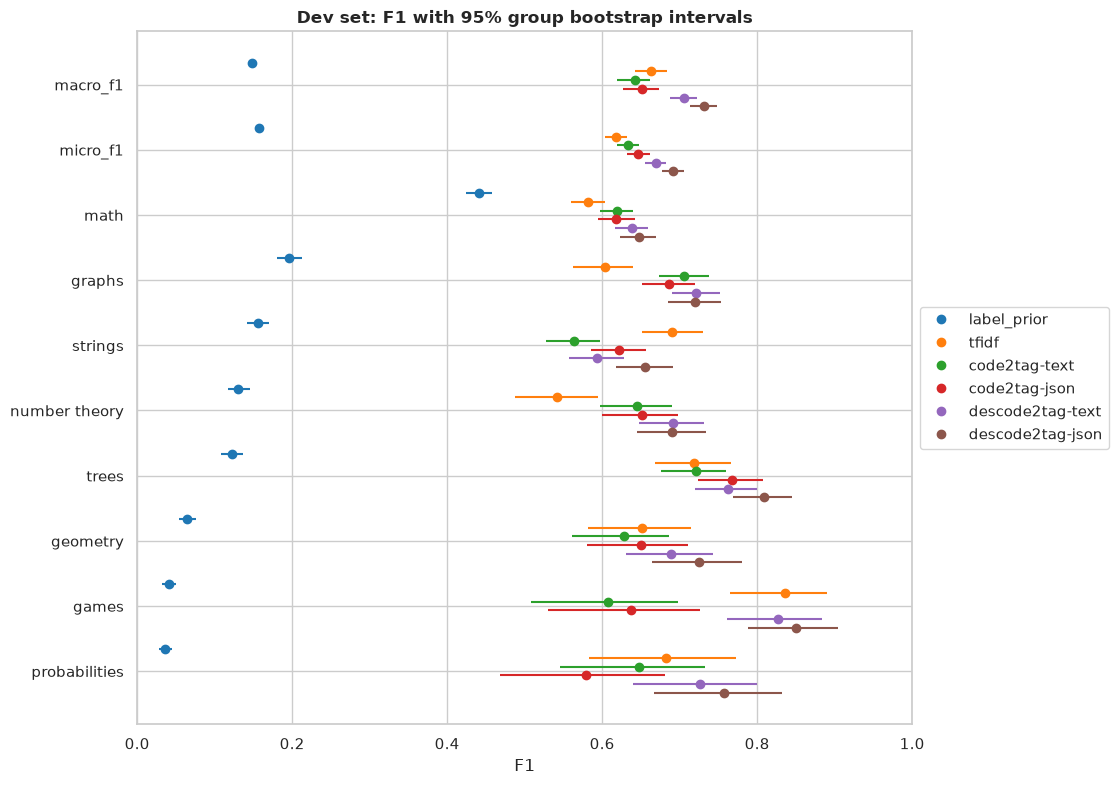

F1 [95% interval]:


method,label_prior,tfidf,code2tag-text,code2tag-json,descode2tag-text,descode2tag-json
metric,,,,,,
macro_f1,"0.149 [0.144, 0.153]","0.663 [0.642, 0.683]","0.642 [0.619, 0.662]","0.651 [0.627, 0.673]","0.706 [0.688, 0.723]","0.732 [0.714, 0.748]"
micro_f1,"0.158 [0.153, 0.163]","0.617 [0.604, 0.632]","0.633 [0.620, 0.647]","0.647 [0.632, 0.661]","0.669 [0.656, 0.682]","0.692 [0.678, 0.705]"
math,"0.441 [0.424, 0.458]","0.582 [0.560, 0.604]","0.619 [0.597, 0.640]","0.618 [0.595, 0.642]","0.638 [0.617, 0.659]","0.647 [0.622, 0.670]"
graphs,"0.196 [0.181, 0.212]","0.603 [0.563, 0.639]","0.705 [0.673, 0.738]","0.686 [0.651, 0.720]","0.721 [0.690, 0.752]","0.720 [0.685, 0.753]"
strings,"0.156 [0.141, 0.170]","0.690 [0.652, 0.730]","0.564 [0.528, 0.597]","0.621 [0.585, 0.657]","0.593 [0.557, 0.628]","0.655 [0.617, 0.691]"
number theory,"0.130 [0.117, 0.145]","0.541 [0.487, 0.595]","0.645 [0.598, 0.690]","0.652 [0.600, 0.697]","0.691 [0.647, 0.732]","0.690 [0.644, 0.734]"
trees,"0.123 [0.109, 0.136]","0.719 [0.668, 0.766]","0.721 [0.676, 0.760]","0.767 [0.724, 0.807]","0.763 [0.720, 0.799]","0.809 [0.769, 0.845]"
geometry,"0.065 [0.054, 0.076]","0.652 [0.581, 0.715]","0.628 [0.561, 0.687]","0.650 [0.580, 0.710]","0.689 [0.631, 0.744]","0.725 [0.664, 0.780]"
games,"0.041 [0.033, 0.050]","0.835 [0.765, 0.891]","0.608 [0.508, 0.698]","0.638 [0.530, 0.726]","0.827 [0.761, 0.883]","0.851 [0.789, 0.905]"


Paired difference with tfidf [95% interval]:


method,label_prior,code2tag-text,code2tag-json,descode2tag-text,descode2tag-json
metric,,,,,
macro_f1,"-0.514 [-0.534, -0.494]","-0.021 [-0.043, +0.002]","-0.012 [-0.036, +0.012]","+0.043 [+0.025, +0.061]","+0.069 [+0.051, +0.087]"
micro_f1,"-0.460 [-0.473, -0.447]","+0.016 [+0.001, +0.030]","+0.029 [+0.013, +0.046]","+0.052 [+0.038, +0.066]","+0.074 [+0.059, +0.089]"
math,"-0.141 [-0.160, -0.123]","+0.037 [+0.015, +0.057]","+0.036 [+0.011, +0.062]","+0.056 [+0.035, +0.078]","+0.065 [+0.041, +0.090]"
graphs,"-0.407 [-0.442, -0.369]","+0.102 [+0.065, +0.141]","+0.083 [+0.041, +0.125]","+0.118 [+0.084, +0.154]","+0.117 [+0.078, +0.155]"
strings,"-0.534 [-0.571, -0.498]","-0.126 [-0.164, -0.090]","-0.069 [-0.104, -0.035]","-0.097 [-0.134, -0.061]","-0.035 [-0.073, +0.002]"
number theory,"-0.411 [-0.463, -0.359]","+0.104 [+0.046, +0.161]","+0.111 [+0.050, +0.170]","+0.150 [+0.096, +0.204]","+0.149 [+0.097, +0.204]"
trees,"-0.596 [-0.641, -0.547]","+0.002 [-0.047, +0.047]","+0.049 [+0.003, +0.094]","+0.044 [-0.002, +0.088]","+0.091 [+0.048, +0.134]"
geometry,"-0.587 [-0.649, -0.519]","-0.023 [-0.091, +0.044]","-0.002 [-0.068, +0.066]","+0.037 [-0.024, +0.101]","+0.073 [+0.013, +0.137]"
games,"-0.794 [-0.850, -0.726]","-0.227 [-0.326, -0.135]","-0.198 [-0.299, -0.106]","-0.009 [-0.068, +0.053]","+0.015 [-0.044, +0.079]"


In [12]:
dev_scores = method_scores(
    focus_truth["dev"],
    {name: predictions[name].loc["dev"][focus] for name in COMPARED},
    problems["dev"]["group"],
    baseline="tfidf",
)
tfidf_dev = dev_scores.at[("tfidf", "macro_f1"), "f1"]
assert tfidf_dev == 0.6629367124205685, f"{tfidf_dev!r}: not tfidf's frozen out-of-fold macro F1"
ax = plot_method_f1(dev_scores)
ax.figure.set_size_inches(10, 9)
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
ax.set(title="Dev set: F1 with 95% group bootstrap intervals")
plt.show()
metrics = ["macro_f1", "micro_f1", *focus]
three = "{:.3f}".format
signed = "{:+.3f}".format
dev_f1 = (
    dev_scores["f1"].map(three)
    + " ["
    + dev_scores["f1_low"].map(three)
    + ", "
    + dev_scores["f1_high"].map(three)
    + "]"
)
print("F1 [95% interval]:")
display(dev_f1.unstack("method").reindex(index=metrics, columns=list(COMPARED)))
dev_delta = (
    dev_scores["delta"].map(signed)
    + " ["
    + dev_scores["delta_low"].map(signed)
    + ", "
    + dev_scores["delta_high"].map(signed)
    + "]"
)
print("Paired difference with tfidf [95% interval]:")
dev_delta.unstack("method").reindex(
    index=metrics, columns=[name for name in COMPARED if name != "tfidf"]
)

- **DesCode2Tag beats TF-IDF; Code2Tag does not.** `descode2tag-json` scores 0.732
  [0.714, 0.748], a paired +0.069 [+0.051, +0.087] over `tfidf`'s 0.663, and
  `descode2tag-text` 0.706, +0.043 [+0.025, +0.061]. From the solution alone, `code2tag-text`
  (0.642, -0.021 [-0.043, +0.002]) and `code2tag-json` (0.651, -0.012 [-0.036, +0.012]) are on
  par with `tfidf`, which reads the statement as well as the solution.
- **Per tag, the LLM reads the subject, TF-IDF the wording.** All four zero-shot methods beat
  `tfidf` on `graphs` (+0.08 to +0.12), `number theory` (+0.10 to +0.15) and `math` (+0.04 to
  +0.07), each interval above 0. `tfidf` keeps `strings` against all four (-0.03 to -0.13;
  only `descode2tag-json`'s interval includes 0), and `games` against the two Code2Tag methods
  (-0.23 and -0.20): a game is in the statement's story, not in the solution.
- `label_prior` scores 0.149: every method is far above the floor.

**Precision and recall per tag**, on dev, as point estimates (`evaluate()` bootstraps the F1
only), then the share of the problems with no focus tag (46% of the dev set) that get no focus
tag predicted (`no_focus_nothing_predicted`):

In [13]:
dev_evaluations = {
    name: evaluate(
        focus_truth["dev"],
        predictions[name].loc["dev"][focus],
        release_years=release_years(problems["dev"]),
        groups=problems["dev"]["group"],
    )
    for name in COMPARED
}
precision_recall = {
    metric: pd.DataFrame(
        {name: dev_evaluations[name].per_tag.loc[ALL_PROBLEMS, metric] for name in COMPARED}
    )
    for metric in ("precision", "recall")
}
display(pd.concat(precision_recall, names=["metric"]).round(3))
pd.Series(
    {
        name: dev_evaluations[name].summary.at[ALL_PROBLEMS, "no_focus_nothing_predicted"]
        for name in COMPARED
    },
    name="no_focus_nothing_predicted",
).round(3)

label_prior  tfidf  code2tag-text  code2tag-json  \
metric    tag                                                               
precision math                 0.283  0.477          0.507          0.628   
          graphs               0.109  0.602          0.661          0.739   
          strings              0.085  0.652          0.403          0.481   
          number theory        0.070  0.595          0.583          0.676   
          trees                0.065  0.774          0.666          0.798   
          geometry             0.033  0.656          0.547          0.619   
          games                0.021  0.892          0.703          0.815   
          probabilities        0.019  0.776          0.710          0.745   
recall    math                 1.000  0.745          0.794          0.609   
          graphs               1.000  0.604          0.756          0.641   
          strings              1.000  0.733          0.935          0.878   
          number theory        1.000  0.496          0.723          0.629   
          trees                1.000  0.670          0.785          0.739   
          geometry             1.000  0.647          0.737          0.684   
          games                1.000  0.786          0.536          0.524   
          probabilities        1.000  0.608          0.595          0.473   

                         descode2tag-text  descode2tag-json  
metric    tag                                                
precision math                      0.547             0.645  
          graphs                    0.644             0.741  
          strings                   0.438             0.537  
          number theory             0.628             0.722  
          trees                     0.696             0.814  
          geometry                  0.572             0.655  
          games                     0.779             0.822  
          probabilities             0.687             0.803  
recall    math                      0.767             0.650  
          graphs                    0.820             0.700  
          strings                   0.920             0.840  
          number theory             0.770             0.662  
          trees                     0.843             0.805  
          geometry                  0.865             0.812  
          games                     0.881             0.881  
          probabilities             0.770             0.716

label_prior         0.000
tfidf               0.531
code2tag-text       0.434
code2tag-json       0.664
descode2tag-text    0.502
descode2tag-json    0.696
Name: no_focus_nothing_predicted, dtype: float64

Free text trades precision for recall. `descode2tag-text` finds more of each tag's problems
than `tfidf` does, on every tag, but is less precise on five of them, and on `strings` most of
all (0.438 against 0.652): it names `strings` for problems that merely read a string.
Structured output names fewer tags (section 2): each `json` method is more precise than its
`text` twin on every tag, with lower or equal recall. On the problems with no focus tag,
`descode2tag-json` predicts none for 70% of them, against 53% for `tfidf` and 43% for
`code2tag-text`.

**Test set, scored once.** Each method's test predictions are scored on their own, each with
its own interval, side by side: there is no paired difference on test, and nothing was chosen
or changed because of these scores ([ADR 0001](../docs/adr/0001-model-selection-protocol.md),
[ADR 0003](../docs/adr/0003-api-methods-are-fixed-reference-models.md)). The cell fails unless
`tfidf`'s test macro F1 is `TFIDF_TEST_MACRO_F1`, the score frozen by `tuning freeze`. Below
each method's F1, its precision and recall per tag, as point estimates:

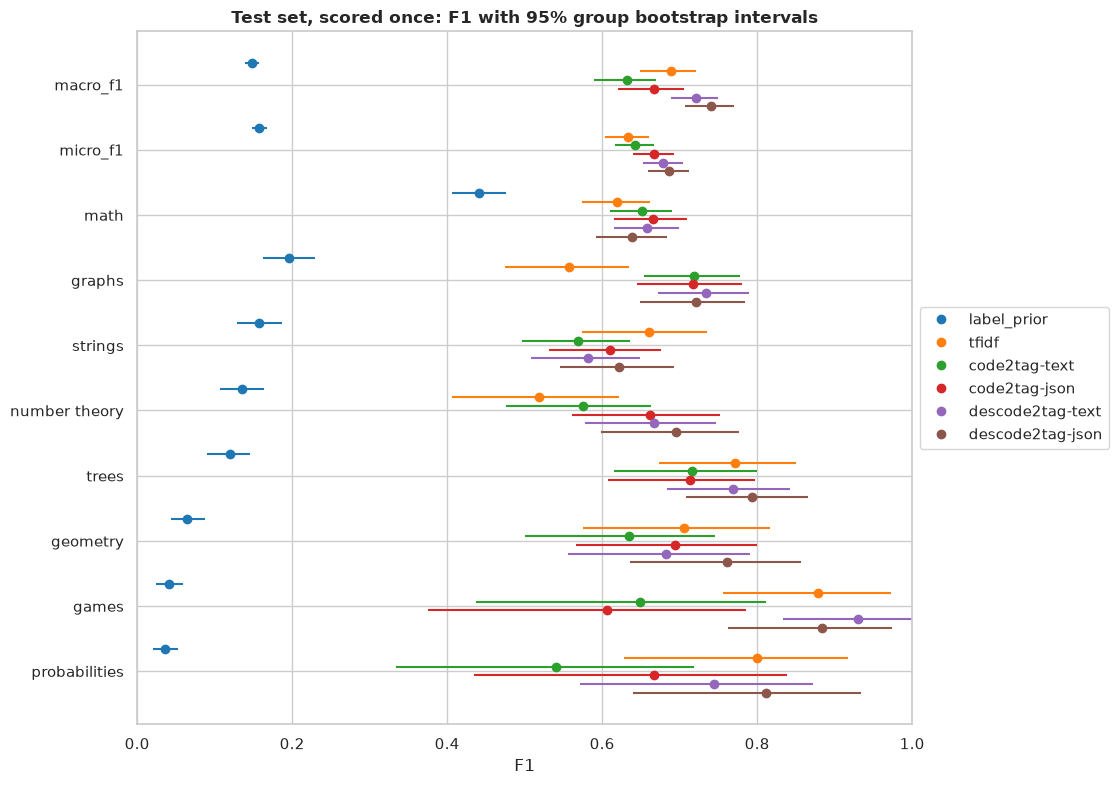

F1 [95% interval], each method on its own:


method,label_prior,tfidf,code2tag-text,code2tag-json,descode2tag-text,descode2tag-json
metric,,,,,,
macro_f1,"0.149 [0.139, 0.158]","0.689 [0.649, 0.721]","0.631 [0.590, 0.669]","0.667 [0.621, 0.705]","0.721 [0.689, 0.750]","0.741 [0.706, 0.770]"
micro_f1,"0.158 [0.148, 0.168]","0.633 [0.604, 0.661]","0.642 [0.616, 0.667]","0.667 [0.640, 0.692]","0.678 [0.653, 0.705]","0.686 [0.659, 0.711]"
math,"0.441 [0.407, 0.475]","0.619 [0.574, 0.662]","0.651 [0.611, 0.689]","0.665 [0.616, 0.710]","0.658 [0.615, 0.699]","0.638 [0.592, 0.684]"
graphs,"0.196 [0.163, 0.229]","0.557 [0.474, 0.634]","0.718 [0.654, 0.777]","0.717 [0.644, 0.780]","0.734 [0.672, 0.790]","0.721 [0.649, 0.784]"
strings,"0.158 [0.128, 0.187]","0.660 [0.574, 0.736]","0.568 [0.496, 0.636]","0.610 [0.532, 0.676]","0.582 [0.509, 0.649]","0.622 [0.545, 0.692]"
number theory,"0.135 [0.107, 0.164]","0.518 [0.406, 0.622]","0.575 [0.476, 0.663]","0.662 [0.561, 0.751]","0.667 [0.577, 0.747]","0.695 [0.599, 0.777]"
trees,"0.119 [0.090, 0.145]","0.772 [0.674, 0.850]","0.715 [0.615, 0.800]","0.713 [0.608, 0.797]","0.769 [0.684, 0.843]","0.794 [0.709, 0.866]"
geometry,"0.064 [0.043, 0.087]","0.706 [0.576, 0.817]","0.634 [0.500, 0.745]","0.693 [0.566, 0.800]","0.683 [0.556, 0.791]","0.761 [0.636, 0.857]"
games,"0.041 [0.024, 0.059]","0.878 [0.755, 0.973]","0.649 [0.438, 0.811]","0.606 [0.375, 0.786]","0.930 [0.833, 1.000]","0.884 [0.762, 0.974]"


Precision and recall per tag, each method on its own (no interval):


label_prior  tfidf  code2tag-text  code2tag-json  \
metric    tag                                                               
precision math                 0.283  0.515          0.532          0.665   
          graphs               0.109  0.550          0.642          0.731   
          strings              0.086  0.587          0.405          0.463   
          number theory        0.072  0.537          0.523          0.658   
          trees                0.063  0.863          0.662          0.788   
          geometry             0.033  0.686          0.531          0.619   
          games                0.021  0.900          0.750          0.833   
          probabilities        0.018  0.727          0.526          0.833   
recall    math                 1.000  0.776          0.840          0.665   
          graphs               1.000  0.565          0.815          0.704   
          strings              1.000  0.753          0.953          0.894   
          number theory        1.000  0.500          0.639          0.667   
          trees                1.000  0.698          0.778          0.651   
          geometry             1.000  0.727          0.788          0.788   
          games                1.000  0.857          0.571          0.476   
          probabilities        1.000  0.889          0.556          0.556   

                         descode2tag-text  descode2tag-json  
metric    tag                                                
precision math                      0.562             0.633  
          graphs                    0.635             0.712  
          strings                   0.426             0.504  
          number theory             0.591             0.710  
          trees                     0.688             0.794  
          geometry                  0.571             0.711  
          games                     0.909             0.864  
          probabilities             0.640             0.789  
recall    math                      0.794             0.644  
          graphs                    0.870             0.731  
          strings                   0.918             0.812  
          number theory             0.764             0.681  
          trees                     0.873             0.794  
          geometry                  0.848             0.818  
          games                     0.952             0.905  
          probabilities             0.889             0.833

In [14]:
test_evaluations = {
    name: evaluate(
        focus_truth["test"],
        predictions[name].loc["test"][focus],
        release_years=release_years(problems["test"]),
        groups=problems["test"]["group"],
    )
    for name in COMPARED
}
tfidf_test = test_evaluations["tfidf"].macro_f1
assert tfidf_test == TFIDF_TEST_MACRO_F1, f"{tfidf_test!r}: not tfidf's frozen test macro F1"
test_precision_recall = {
    metric: pd.DataFrame(
        {name: test_evaluations[name].per_tag.loc[ALL_PROBLEMS, metric] for name in COMPARED}
    )
    for metric in ("precision", "recall")
}
test_scores = method_scores(
    focus_truth["test"],
    {name: predictions[name].loc["test"][focus] for name in COMPARED},
    problems["test"]["group"],
)
ax = plot_method_f1(test_scores)
ax.figure.set_size_inches(10, 9)
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
ax.set(title="Test set, scored once: F1 with 95% group bootstrap intervals")
plt.show()
test_f1 = (
    test_scores["f1"].map(three)
    + " ["
    + test_scores["f1_low"].map(three)
    + ", "
    + test_scores["f1_high"].map(three)
    + "]"
)
print("F1 [95% interval], each method on its own:")
display(test_f1.unstack("method").reindex(index=metrics, columns=list(COMPARED)))
print("Precision and recall per tag, each method on its own (no interval):")
pd.concat(test_precision_recall, names=["metric"]).round(3)

On test, each method scored on its own: `descode2tag-json` 0.741 [0.706, 0.770],
`descode2tag-text` 0.721 [0.689, 0.750], `code2tag-json` 0.667 [0.621, 0.705] and
`code2tag-text` 0.631 [0.590, 0.669], beside `tfidf`'s 0.689 [0.649, 0.721]. These scores
are reported side by side only: the comparisons are concluded on dev
([ADR 0003](../docs/adr/0003-api-methods-are-fixed-reference-models.md)). With a quarter
of dev's problems, the intervals are about twice as wide.

**Both confusion matrices of each zero-shot method, on dev**, read as in notebook 04: in the
tag confusion matrix, a cell is the share of the row's problems that got the column's tag (a
problem can have and get several tags, so a row need not sum to 1); in the per-tag matrices,
TP and FN on the first row, FP and TN on the second. Those of `tfidf` are in notebook 04,
section 4. Errors are read on dev only:

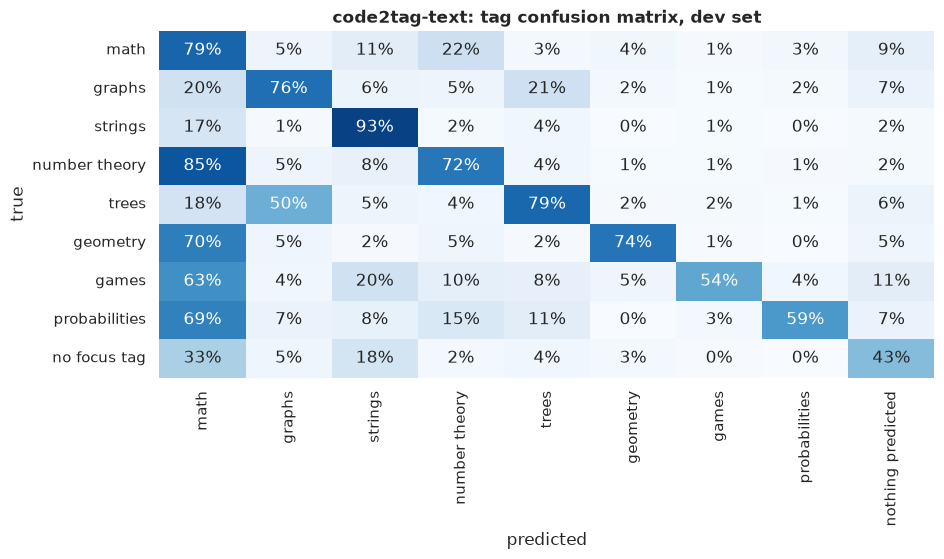

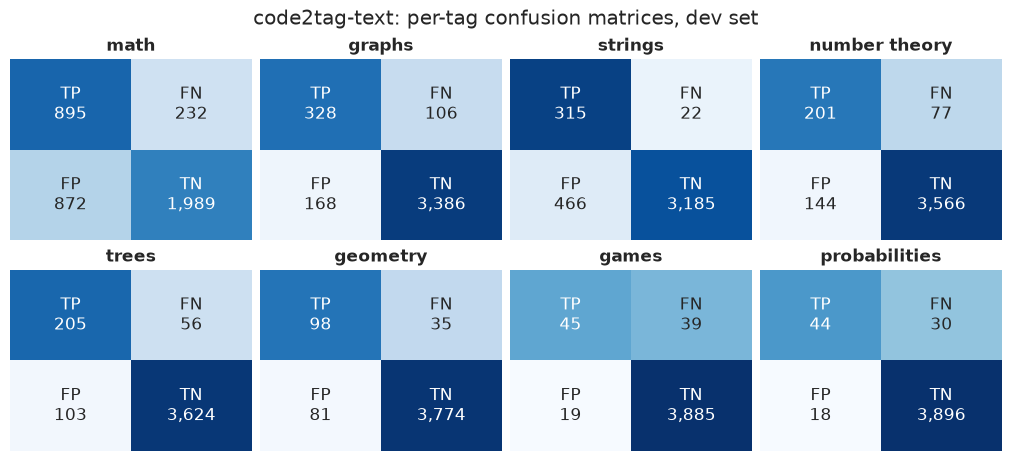

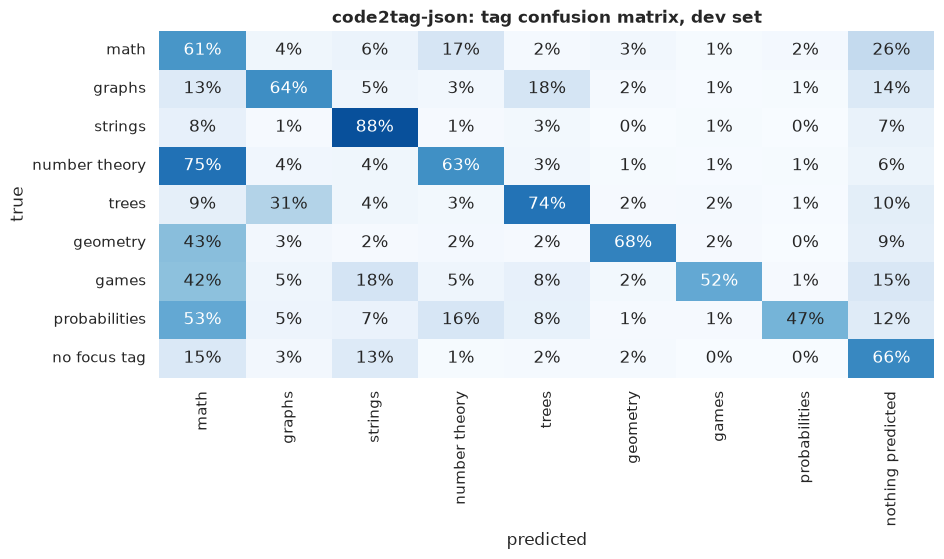

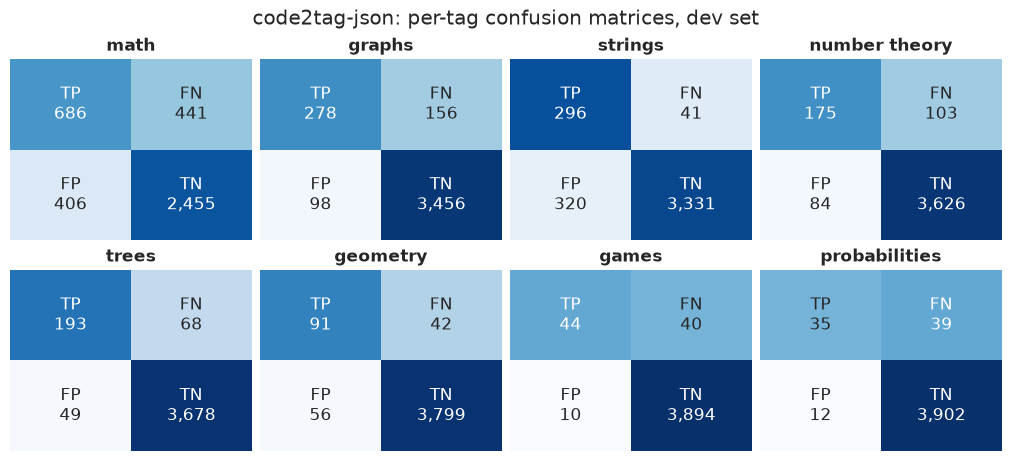

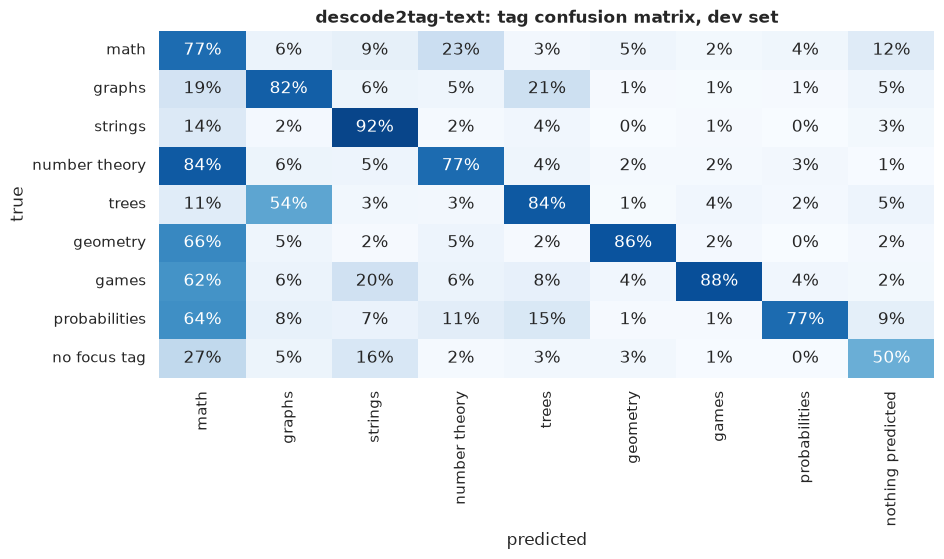

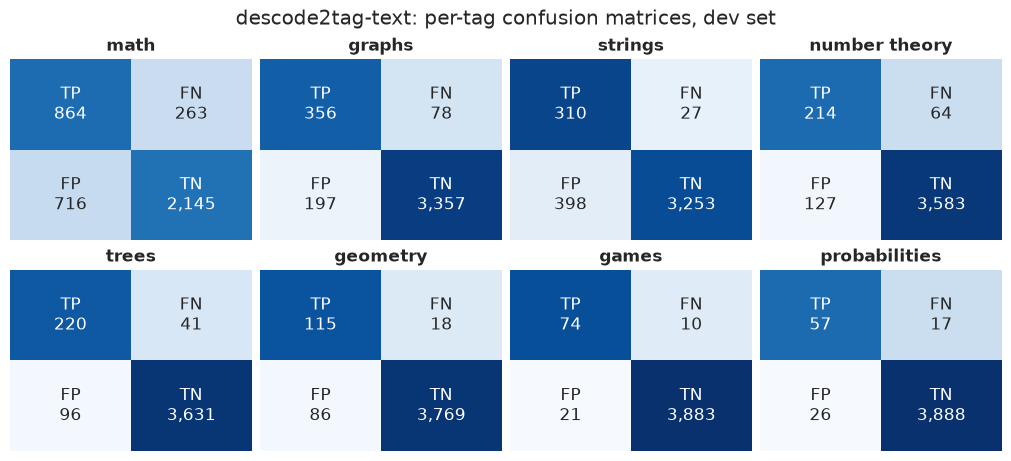

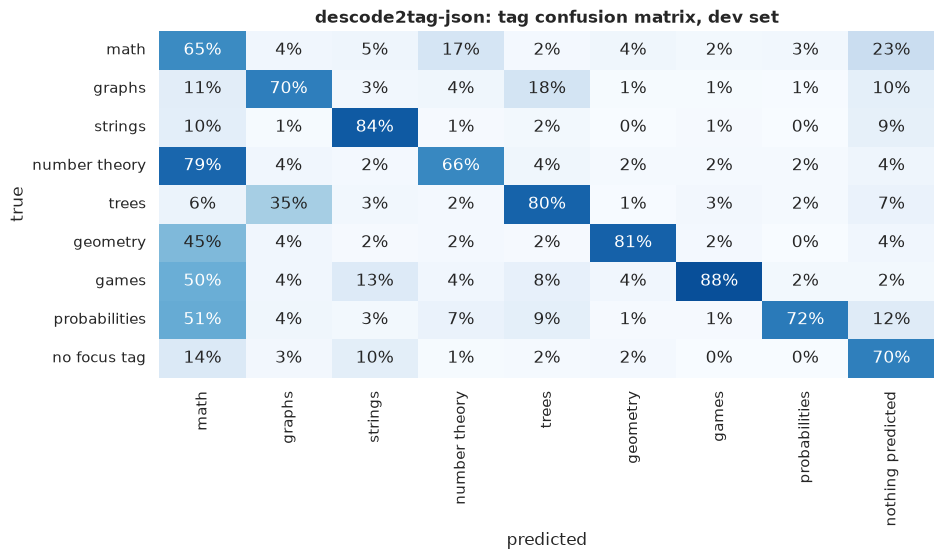

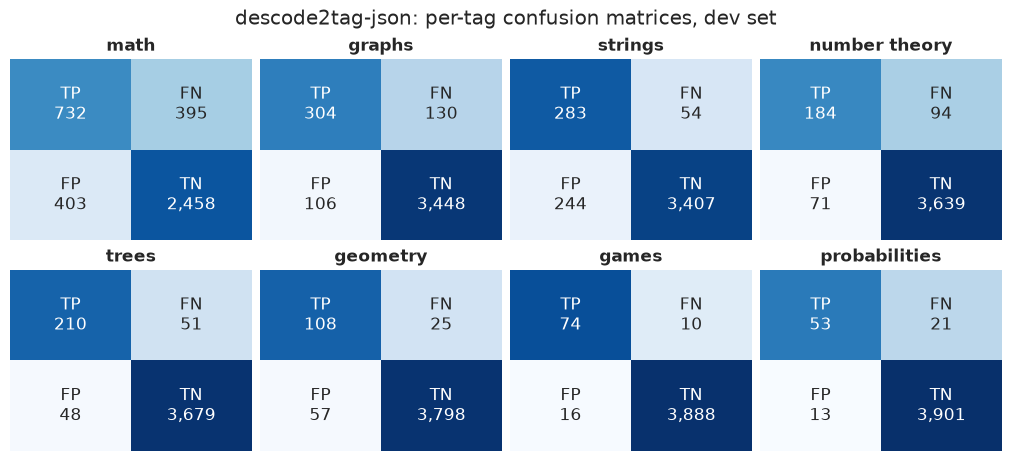

In [15]:
for name in METHOD_NAMES:
    ax = plot_tag_confusion(dev_evaluations[name].tag_confusion)
    ax.set(title=f"{name}: tag confusion matrix, dev set")
    plt.show()
    figure = plot_confusion_grid(dev_evaluations[name].per_tag.loc[ALL_PROBLEMS])
    figure.suptitle(f"{name}: per-tag confusion matrices, dev set")
    plt.show()

`math` draws in the other tags: the zero-shot methods name it for 75% to 85% of the
`number theory` problems, and for 42% to 70% of the `geometry`, `games` and `probabilities`
ones. Many of those problems carry `math` too, so part of it is right: a cell also counts the
problems that have both tags. The false positives of the problems with no focus tag go mostly
to `math` (14% to 33% of them) and `strings` (10% to 18%).

## 5. Free text against structured output

The two formats of a setting send the same prompt; `json` adds a strict schema, so an answer
can only list tags of `ALL_TAGS`. Which format is better was decided on dev, before the first
test request, by a metric fixed before any answer existed: per setting, the dev focus macro F1
of `json` minus `text`, paired, with its group bootstrap interval. `json` is better when the
interval is above 0, `text` when it is below, and otherwise no difference is detected. The
conclusion was recorded in commit `b478840`, "Conclude text against json on dev: json better
for DesCode2Tag, no difference for Code2Tag", which precedes every test answers file. The cell
computes it again, and fails unless it reaches the same conclusion:

In [16]:
format_deltas = pd.concat(
    {
        setting: compare(
            focus_truth["dev"],
            predictions[f"{setting}-text"].loc["dev"][focus],
            predictions[f"{setting}-json"].loc["dev"][focus],
            problems["dev"]["group"],
        )
        for setting in SETTINGS
    },
    names=["setting"],
).rename(columns={"baseline": "text", "candidate": "json"})
code2tag_macro = format_deltas.loc[("code2tag", "macro_f1")]
descode2tag_macro = format_deltas.loc[("descode2tag", "macro_f1")]
assert code2tag_macro["delta_low"] <= 0 <= code2tag_macro["delta_high"], "Code2Tag: a difference"
assert descode2tag_macro["delta_low"] > 0, "DesCode2Tag: json not better"
format_deltas.round(4)

text    json   delta  delta_low  delta_high
setting     metric                                                      
code2tag    macro_f1       0.6421  0.6514  0.0093    -0.0040      0.0227
            micro_f1       0.6333  0.6466  0.0134     0.0031      0.0241
            math           0.6185  0.6183 -0.0002    -0.0199      0.0202
            graphs         0.7054  0.6864 -0.0190    -0.0432      0.0059
            strings        0.5635  0.6212  0.0577     0.0387      0.0769
            number theory  0.6453  0.6518  0.0065    -0.0255      0.0372
            trees          0.7206  0.7674  0.0468     0.0202      0.0766
            geometry       0.6282  0.6500  0.0218    -0.0170      0.0597
            games          0.6081  0.6377  0.0296    -0.0141      0.0732
            probabilities  0.6471  0.5785 -0.0685    -0.1436      0.0057
descode2tag macro_f1       0.7061  0.7319  0.0258     0.0142      0.0370
            micro_f1       0.6692  0.6915  0.0223     0.0125      0.0318
            math           0.6383  0.6472  0.0089    -0.0083      0.0260
            graphs         0.7214  0.7204 -0.0010    -0.0271      0.0243
            strings        0.5933  0.6551  0.0618     0.0397      0.0842
            number theory  0.6914  0.6904 -0.0010    -0.0343      0.0316
            trees          0.7626  0.8092  0.0467     0.0229      0.0720
            geometry       0.6886  0.7248  0.0362    -0.0034      0.0748
            games          0.8268  0.8506  0.0238    -0.0088      0.0584
            probabilities  0.7261  0.7571  0.0310    -0.0216      0.0796

For DesCode2Tag, `json` is better: +0.0258 [+0.0142, +0.0370]. For Code2Tag, no difference is
detected: +0.0093 [-0.0040, +0.0227]. Per tag, the differences whose intervals exclude 0 favour
`json`, on `strings` (+0.058 and +0.062) and `trees` (+0.047 in both settings), two tags that
free text names too often (section 4); no tag's interval lies below 0. Micro F1 favours
`json` in both settings.

**Beside it, deciding nothing**: each method's focus macro F1 on dev and on test, side by side;
then, per part, the failed answers, the unknown pieces and the empty answers, the tokens of an
average request and its answer, and the median latency of one request (`per_problem.csv`):

In [17]:
display(
    pd.DataFrame(
        {
            "dev macro F1": {name: dev_evaluations[name].macro_f1 for name in METHOD_NAMES},
            "test macro F1": {name: test_evaluations[name].macro_f1 for name in METHOD_NAMES},
        }
    ).round(4)
)
per_answer = calls.groupby(["method", "part"], sort=False).agg(
    input_tokens=("input_tokens", "mean"),
    output_tokens=("output_tokens", "mean"),
    median_latency_s=("latency_s", "median"),
)
health[["failed", "unknown_pieces", "empty_answers"]].join(per_answer).round(2)

,dev macro F1,test macro F1
code2tag-text,0.6421,0.6314
code2tag-json,0.6514,0.6668
descode2tag-text,0.7061,0.7209
descode2tag-json,0.7319,0.7407


failed  unknown_pieces  empty_answers  input_tokens  \
method           part                                                        
code2tag-text    dev        0              90              0        556.98   
                 test       0              24              0        522.90   
code2tag-json    dev        0               0              0        703.98   
                 test       0               0              0        669.90   
descode2tag-text dev        0              47              0       1085.58   
                 test       0              18              0       1051.93   
descode2tag-json dev        0               0              0       1232.58   
                 test       0               0              0       1198.93   

                       output_tokens  median_latency_s  
method           part                                   
code2tag-text    dev           11.76              1.08  
                 test          11.77              1.12  
code2tag-json    dev           19.53              1.06  
                 test          19.49              1.08  
descode2tag-text dev           11.67              1.02  
                 test          11.65              1.08  
descode2tag-json dev           19.66              1.16  
                 test          19.64              1.03

On test, each method's macro F1 is reported beside the others', not compared: 0.631 for
`code2tag-text` and 0.667 for `code2tag-json`, 0.721 for `descode2tag-text` and 0.741 for
`descode2tag-json`. Neither format fails more: no answer failed in either. Structured output
costs more: the schema adds 147 input tokens to every request (26% more for Code2Tag, 14% for
DesCode2Tag), and a JSON answer is about two thirds longer than a free-text one (19.5 output
tokens against 11.7). The median request takes about a second in both formats.

## 6. Slices

`evaluate()` scores each method on slices of a part: all problems; the focus-tagged ones, which
leaves out the problems with no focus tag (46% of each part) and their false positives; and the
two release eras, split at 2018, when statements switched to `$$$` LaTeX (notebook 04). One more
slice leaves out the self-identifying solutions, whose code names its own problem (a Codeforces
URL, a contest id) or quotes its statement: 50 dev and 16 test problems, frozen in
`assets/slices/self_identifying_solutions.csv` before the first request. The macro F1 of each
method on each slice, each method on its own; the cell fails unless every problem was released
before `gpt-6-luna`'s knowledge cutoff, 2026-05-18:

In [18]:
latest = df["prob_desc_created_at"].max()
assert latest < pd.Timestamp("2026-05-18", tz="UTC"), "a problem after the knowledge cutoff"
slice_f1, slice_sizes = {}, {}
for part, evaluations in {"dev": dev_evaluations, "test": test_evaluations}.items():
    kept = problems[part].index.difference(contamination.index)
    for name in COMPARED:
        row = evaluations[name].summary["macro_f1"].to_dict()
        row["without the self-identifying"] = evaluate(
            focus_truth[part].loc[kept], predictions[name].loc[part].loc[kept, focus]
        ).macro_f1
        slice_f1[(part, name)] = row
    sizes = evaluations["tfidf"].summary["problems"].to_dict()
    slice_sizes[part] = sizes | {"without the self-identifying": len(kept)}
print(f"latest release: {latest:%Y-%m-%d}")
for part, sizes in slice_sizes.items():
    print(f"{part} problems per slice: {sizes}")
pd.DataFrame(slice_f1).T.round(3)

latest release: 2022-11-21
dev problems per slice: {'all problems': 3988, 'focus-tagged': 2143, 'up to 2017': 1626, 'from 2018': 2362, 'without the self-identifying': 3938}
test problems per slice: {'all problems': 994, 'focus-tagged': 535, 'up to 2017': 407, 'from 2018': 587, 'without the self-identifying': 978}


all problems  focus-tagged  up to 2017  from 2018  \
dev  label_prior              0.149         0.250       0.128      0.161   
     tfidf                    0.663         0.729       0.662      0.653   
     code2tag-text            0.642         0.744       0.639      0.631   
     code2tag-json            0.651         0.722       0.669      0.624   
     descode2tag-text         0.706         0.808       0.689      0.710   
     descode2tag-json         0.732         0.803       0.742      0.720   
test label_prior              0.149         0.250       0.128      0.162   
     tfidf                    0.689         0.752       0.639      0.705   
     code2tag-text            0.631         0.744       0.607      0.642   
     code2tag-json            0.667         0.738       0.675      0.660   
     descode2tag-text         0.721         0.821       0.665      0.746   
     descode2tag-json         0.741         0.807       0.708      0.747   

                       without the self-identifying  
dev  label_prior                              0.148  
     tfidf                                    0.663  
     code2tag-text                            0.641  
     code2tag-json                            0.650  
     descode2tag-text                         0.706  
     descode2tag-json                         0.733  
test label_prior                              0.149  
     tfidf                                    0.689  
     code2tag-text                            0.633  
     code2tag-json                            0.670  
     descode2tag-text                         0.721  
     descode2tag-json                         0.741

- **Without the 50 self-identifying solutions of dev**, the largest move of a method's macro
  F1 is 0.001: the model's score does not come from the problems whose solution gives them
  away. On test, without its 16, the largest move is 0.003 (`code2tag-json`), reported only.
  That does not rule out contamination: every problem, with its tags, is on Codeforces, and
  the model may know it whatever its solution says.
- **The release era cannot reveal memorisation here.** Every problem was released by
  2022-11-21, years before the model's knowledge cutoff, so both eras are inside its training
  period. The gaps between the eras go either way from method to method and part to part
  (`descode2tag-json`: 0.742 up to 2017 against 0.720 from 2018 on dev, 0.708 against 0.747 on
  test), by up to 0.08, as `tfidf`'s do (0.639 against 0.705 on test).
- **On the focus-tagged problems** the DesCode2Tag methods lead by more: 0.808 and 0.803
  against `tfidf`'s 0.729 on dev. The problems with no focus tag cost them more than they cost
  `tfidf` (section 4).

## 7. Where TF-IDF and the LLM disagree, on dev

Errors are read on dev only. For each focus tag, the dev problems that both `tfidf` and the
zero-shot method with the best dev macro F1 get right (a true negative counts as right), that
only one of them gets right, or neither (`agreement()`). The cell prints which method that is:
choosing it on dev is allowed.

In [19]:
dev_macro_f1 = dev_scores.xs("macro_f1", level="metric")["f1"]
best = dev_macro_f1[list(METHOD_NAMES)].idxmax()
dev_tfidf = predictions["tfidf"].loc["dev"]
dev_best = predictions[best].loc["dev"][focus]
print(f"the zero-shot method with the best dev macro F1: {best}")
agreement(focus_truth["dev"], dev_tfidf, dev_best).rename(
    columns={"only_a_right": "only tfidf right", "only_b_right": f"only {best} right"}
)

the zero-shot method with the best dev macro F1: descode2tag-json


,both_right,only tfidf right,only descode2tag-json right,both_wrong
tag,,,,
math,2379,402,811,396
graphs,3549,94,203,142
strings,3595,171,95,127
number theory,3688,66,135,99
trees,3814,37,75,62
geometry,3862,34,44,48
games,3949,13,13,13
probabilities,3939,7,15,27


`descode2tag-json` is right alone more often than `tfidf` on every tag but `strings` (95
problems against 171) and `games` (13 each). `math` divides them most: 811 problems only the
LLM gets right, 402 only `tfidf`, and 396 neither. The two are wrong in different places, which
a combination of them could use (section 10).

**A few examples**: for each tag, the first two dev problems, by sample id, where exactly one of
the two is right (`disagreements()`), with all their tags and the start of their statement:

In [20]:
examples = pd.concat(
    {
        tag: disagreements(focus_truth["dev"], dev_tfidf, dev_best, tag, limit=2)
        for tag in FOCUS_TAGS
    },
    names=["tag"],
).rename(columns={"a": "tfidf", "b": best})
read = problems["dev"].loc[examples.index.get_level_values("sample_id")]
examples.assign(
    tags=read["tags"].to_numpy(),
    statement=read["statement"].str[:ERROR_EXCERPT_CHARS].to_numpy(),
)

truth  tfidf  descode2tag-json  \
tag           sample_id                                   
math          0              1      1                 0   
              4              1      1                 0   
graphs        27             1      0                 1   
              34             1      1                 0   
strings       41             1      0                 1   
              59             0      0                 1   
number theory 9              1      0                 1   
              23             1      0                 1   
trees         10             0      1                 0   
              173            1      0                 1   
geometry      113            0      1                 0   
              245            0      1                 0   
games         346            1      0                 1   
              350            0      1                 0   
probabilities 686            0      0                 1   
              790            1      1                 0   

                                                                                             tags  \
tag           sample_id                                                                             
math          0          [greedy, constructive algorithms, math, implementation, data structures]   
              4                            [binary search, divide and conquer, brute force, math]   
graphs        27                                          [binary search, graphs, shortest paths]   
              34                                                 [dfs and similar, trees, graphs]   
strings       41                                             [two pointers, brute force, strings]   
              59                                          [constructive algorithms, greedy, math]   
number theory 9                                                   [number theory, math, matrices]   
              23          [greedy, number theory, bitmasks, math, implementation, ternary search]   
trees         10                                                            [dsu, greedy, graphs]   
              173                                 [combinatorics, dfs and similar, trees, graphs]   
geometry      113                                    [combinatorics, binary search, two pointers]   
              245                          [constructive algorithms, implementation, brute force]   
games         346                                   [constructive algorithms, games, interactive]   
              350                                                                [implementation]   
probabilities 686                                              [interactive, number theory, math]   
              790                                              [dp, combinatorics, probabilities]   

                                                                                                                             statement  
tag           sample_id                                                                                                                 
math          0          Numbers $$$1, 2, 3, \dots n$$$ (each integer from $$$1$$$ to $$$n$$$ once) are written on a board. In one ...  
              4          Thanos wants to destroy the avengers base, but he needs to destroy the avengers along with their base. Let...  
graphs        27         Yaroslav is playing a game called "Time". The game has a timer showing the lifespan he's got left. As soon...  
              34         Kefa decided to celebrate his first big salary by going to the restaurant. He lives by an unusual park. Th...  
strings       41         Recently Polycarp noticed that some of the buttons of his keyboard are malfunctioning. For simplicity, we ...  
              59         Polycarp and his friends want to visit a new restaurant. The restaurant has $$$n$$$ tables arranged along ...  
number theory 9          You are given two inte

Problem 0, whose request section 1 shows, is a `math` problem that `descode2tag-json` did not
tag `math`. `tfidf` follows the statement's words: it reads `games` in problem 350, where
"Alice and Bob play an interesting and tasty game" by eating candies (tagged `implementation`
only), `geometry` in problem 113's points on a line, and `trees` in problem 10, a graph
problem. The LLM names `strings` for problem 59, whose input is a string of 0s and 1s.

## 8. Inference time and cost

The task statement (PROBLEM.md) asks for a single-problem prediction in under 10 seconds.
`python -m codeforces_tags.tracking latency` timed each method on the same 50 dev problems
(`LATENCY_PROBLEMS`, drawn with `LATENCY_SEED`), one problem per call, after loading its method
folder. For a zero-shot method each call was one live request, outside the answers files; its
bulk time is the time 50 problems took at the pace of its answers files, 16 requests in flight.
The seconds per problem (median, 95th percentile, maximum), the time to load the method folder,
the problems per second in bulk, and whether the slowest problem is under the budget:

,median_s,p95_s,max_s,load_s,bulk_problems_per_s,under the budget
label_prior,0.0001,0.0001,0.0001,0.0012,468735.3,True
tfidf,0.0068,0.0080,0.0097,0.8976,901.5,True
code2tag-text,1.0867,2.6545,4.4149,0.0009,12.8,True
code2tag-json,1.1367,1.4850,2.1432,0.0012,13.6,True
descode2tag-text,0.9852,1.5448,1.9751,0.0007,13.5,True
descode2tag-json,1.2134,2.4384,3.6476,0.0008,12.7,True


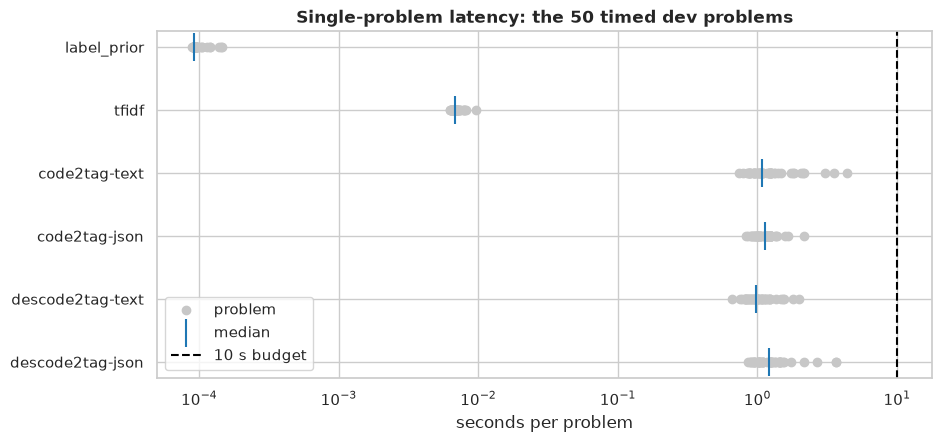

In [21]:
timing = pd.DataFrame(
    {
        name: {
            **latency_summary(latency.seconds).to_dict(),
            "load_s": latency.load_s,
            "bulk_problems_per_s": len(latency.seconds) / latency.bulk_s,
        }
        for name, latency in latencies.items()
    }
).T
timing["under the budget"] = timing["max_s"] < LATENCY_BUDGET_S
rounding = {"median_s": 4, "p95_s": 4, "max_s": 4, "load_s": 4, "bulk_problems_per_s": 1}
display(timing.round(rounding))
ax = plot_latency({name: latency.seconds for name, latency in latencies.items()})
ax.set(title="Single-problem latency: the 50 timed dev problems")
plt.show()

Every method is under the budget. A zero-shot method answers one problem in about a second
(medians from 0.99 to 1.21 s; the slowest of the 200 timed requests took 4.41 s), about 145 to
180 times as long as `tfidf` (6.8 ms), but loads in about a millisecond, against 0.90 s for
`tfidf`'s skops file: its folder holds only its prompt. The API sets that time, not the
problem: it depends on the network and on OpenAI's load, and these 50 requests are one sample
of it. In bulk, 16 requests in flight answer about 13 problems per second.

**Cost and tokens per 1,000 problems** (`cost_per_thousand()`: the mean of each part's
recorded calls, times 1,000), at the prices of `config.LLM_PRICES` (0.10 USD per million input
tokens and 0.50 per million output tokens; no token was cached), then what the study spent:
every answer of the answers files (those of the first, capped runs included) and the 200
timed requests:

In [22]:
per_thousand = cost_per_thousand(per_problem).round(
    {"input_tokens": 0, "output_tokens": 0, "total_cost_usd": 4, "median_latency_s": 3}
)
display(per_thousand.astype({"input_tokens": int, "output_tokens": int}))
spend = pd.DataFrame(
    {
        name: {
            "dev answers": per_problem[name].loc["dev", "total_cost_usd"].sum(),
            "test answers": per_problem[name].loc["test", "total_cost_usd"].sum(),
            "timed requests": latencies[name].calls["cost_usd"].sum(),
        }
        for name in METHOD_NAMES
    }
).T
spend["total"] = spend.sum(axis=1)
print(f"spent in all, in USD: {spend['total'].sum():.6f}")
spend.round(6)

input_tokens  output_tokens  total_cost_usd  \
method           part                                                
code2tag-text    dev         556983          11761          0.0616   
                 test        522897          11770          0.0582   
code2tag-json    dev         703983          19529          0.0802   
                 test        669897          19490          0.0767   
descode2tag-text dev        1085581          11671          0.1144   
                 test       1051926          11648          0.1110   
descode2tag-json dev        1232581          19659          0.1331   
                 test       1198926          19636          0.1297   

                       median_latency_s  
method           part                    
code2tag-text    dev              1.079  
                 test             1.121  
code2tag-json    dev              1.065  
                 test             1.085  
descode2tag-text dev              1.023  
                 test             1.079  
descode2tag-json dev              1.165  
                 test             1.030

spent in all, in USD: 1.944335


,dev answers,test answers,timed requests,total
code2tag-text,0.245575,0.057826,0.002862,0.306263
code2tag-json,0.319690,0.076274,0.003803,0.399768
descode2tag-text,0.456202,0.110350,0.005560,0.572112
descode2tag-json,0.530754,0.128932,0.006507,0.666193


Tagging 1,000 problems costs about 0.06 USD with `code2tag-text` and 0.13 USD with
`descode2tag-json`: input tokens are 88% to 95% of the bill, and the statement doubles the
prompt. The whole study, 19,928 answers and 200 timed requests, cost 1.94 USD.

## 9. Every problem in MLflow

The frozen predictions that this notebook reads are also logged, problem by problem, in an MLflow
store, where one problem can be looked up in the MLflow 3.16.1 UI: its inputs, its true tags, each
method's predicted tags, whether each focus tag is right and, for a zero-shot method, the tokens
and cost of its recorded call. This section shows that store in 13 screenshots.

**What the store holds** (the experiment `tag-methods`, in the local `experiments/` folder;
`assets/` stays the record):
- **Two evaluation datasets**, `codeforces-dev` (3,988 records) and `codeforces-test` (994): one
  record per problem, with its statement fields and its solution as inputs and its true tags and
  focus tags as expectations.
- **One evaluation run per method and part**, `eval-<method>-<part>`, for the six methods of this
  notebook: 12 runs and 29,892 traces, one per problem. A trace holds the problem's inputs, the
  method's predicted tags, 2 expectations and the scorers' feedbacks (`focus_exact_match`,
  `focus_f1`, a `correct_<tag>` per focus tag and, for the four zero-shot methods, which predict
  over 37 tags, `all_tags_jaccard`): 12 or 13 assessments. A zero-shot trace also holds its
  recorded call: the served model, its tokens and its cost. Nothing is asked again: a trace looks
  its prediction up by sample id in the method's frozen predictions.
- **One method run per method**, with its logged model, its dataset-level metrics and its latency
  summary, and **the prompts** `code2tag` and `descode2tag`, each with version 1 (`text`) and
  version 2 (`json`).

**How it was built.** The store is rebuilt from committed files, with no request: each method's
`freeze` or `llm score` (which checks its frozen files and logs the method), `tracking latency`
and `tracking calibrate` (which log the committed timings and `tfidf`'s calibration),
`tracking datasets`, then `tracking evaluate` for each method, every dev run first and every test
run after. Each `tracking evaluate` counts every trace and assessment, and matches a zero-shot
run's summed cost to its `per_problem.csv`.

**Dev only.** As in the rest of this notebook (ADR 0001), the screenshots are of dev: they open
the dev dataset, dev runs and their traces, never a test record, run or trace. The test part is in
the store as one evaluation run per method, made once and not opened here. The pages that list
traces by time (screenshots 10 and 11) show the window of the dev runs, and the script refuses a
store where a test run falls in that window.

**Retaken, not reproduced.** `notebooks/figures/mlflow_ui.py` starts a local MLflow server on the
store and opens its UI in headless Chrome, so the PNGs change a little each time (times, run
colours); the steps are in [`notebooks/README.md`](README.md). The server has no API key and no
job runner, the browser aborts or reports any request that is not the server's own, the
committed PNGs were taken in a network namespace that holds only loopback, and no LLM feature of
the UI (Assistant, Analyze, Detect Issues) was opened. This notebook reads the PNGs and `config`
only.

What the screenshots show is fixed by `config.MLFLOW_SCREEN_SAMPLE_ID`, `MLFLOW_SCREEN_COMPARE`
and `MLFLOW_SCREEN_TAG`. The cell prints them, with the numbers that the screenshots read and the
frozen files give too, and fails unless they are the numbers the screenshots read, and the sum of
the Cost column of screenshot 11 over the run's 3,988 traces, which the screenshot does not show:

In [23]:
screen_truth = focus_truth["dev"][MLFLOW_SCREEN_TAG]
screen_wrong = predictions[MLFLOW_SCREEN_COMPARE].loc["dev", MLFLOW_SCREEN_TAG] != screen_truth
screen_call = per_problem[MLFLOW_SCREEN_COMPARE].loc[("dev", MLFLOW_SCREEN_SAMPLE_ID)]
screen_tokens = screen_call["input_tokens"] + screen_call["output_tokens"]
screen_calls = pd.concat([per_problem[name].loc["dev"] for name in METHOD_NAMES])
screen_sums = screen_calls[["input_tokens", "output_tokens", "total_cost_usd"]].sum()
screen_cost = per_problem[MLFLOW_SCREEN_COMPARE].loc["dev", "total_cost_usd"].sum()
screen_traces = len(COMPARED) * len(problems["dev"])
assert MLFLOW_SCREEN_SAMPLE_ID in problems["dev"].index, "the screens show a dev problem"
assert screen_wrong[MLFLOW_SCREEN_SAMPLE_ID], f"{MLFLOW_SCREEN_COMPARE} is right on problem 0"
# The numbers the screenshots read: 798 rows in 8; 971 tokens and 0.000105 USD in 7; 23,928 traces,
# 14,273,560 input tokens, 249,729 output tokens and 1.552221 USD in 10. Then 0.530754 USD, the sum
# of the Cost column of 11 over the run's 3,988 traces, which it does not show (it shows 25 rows).
assert (
    screen_wrong.sum(),
    screen_tokens,
    round(screen_call["total_cost_usd"], 6),
    screen_traces,
    screen_sums["input_tokens"],
    screen_sums["output_tokens"],
    round(screen_sums["total_cost_usd"], 6),
    round(screen_cost, 6),
) == (
    798,
    971,
    0.000105,
    23_928,
    14_273_560,
    249_729,
    1.552221,
    0.530754,
), "the screenshots read other numbers"
print(
    f"The screenshots show dev problem {MLFLOW_SCREEN_SAMPLE_ID} and {MLFLOW_SCREEN_COMPARE}, "
    f"compared with tfidf, and filter on {MLFLOW_SCREEN_TAG}.\n"
    f"{MLFLOW_SCREEN_COMPARE} gets {MLFLOW_SCREEN_TAG} wrong on {screen_wrong.sum():,} of "
    f"{len(screen_wrong):,} dev problems: the rows of screenshot 8.\n"
    f"Its call for problem {MLFLOW_SCREEN_SAMPLE_ID}: {screen_tokens} tokens and "
    f"{screen_call['total_cost_usd']:.6f} USD: the span header of screenshot 7.\n"
    f"Its {len(screen_wrong):,} dev calls cost {screen_cost:.6f} USD: what the Cost column of "
    f"screenshot 11 sums to over all its rows; the page shows the first 25, and no sum.\n"
    f"The four zero-shot methods' {len(screen_calls):,} dev calls: "
    f"{screen_sums['input_tokens']:,.0f} input and {screen_sums['output_tokens']:,.0f} output "
    f"tokens, {screen_sums['total_cost_usd']:.6f} USD: the Token Usage and the Total Cost of "
    f"screenshot 10, which counts {screen_traces:,} dev traces ({len(COMPARED)} methods, "
    f"{len(problems['dev']):,} problems each)."
)
screen_costs = ", ".join(
    f"{name} {per_problem[name].loc['dev', 'total_cost_usd'].sum():.6f}" for name in METHOD_NAMES
)
print(
    f"By method, which no screenshot sums: {screen_costs} USD, each the summed cost of its dev "
    "run's traces, as tracking evaluate checked."
)

The screenshots show dev problem 0 and descode2tag-json, compared with tfidf, and filter on math.
descode2tag-json gets math wrong on 798 of 3,988 dev problems: the rows of screenshot 8.
Its call for problem 0: 971 tokens and 0.000105 USD: the span header of screenshot 7.
Its 3,988 dev calls cost 0.530754 USD: what the Cost column of screenshot 11 sums to over all its rows; the page shows the first 25, and no sum.
The four zero-shot methods' 15,952 dev calls: 14,273,560 input and 249,729 output tokens, 1.552221 USD: the Token Usage and the Total Cost of screenshot 10, which counts 23,928 dev traces (6 methods, 3,988 problems each).
By method, which no screenshot sums: code2tag-text 0.245575, code2tag-json 0.319690, descode2tag-text 0.456202, descode2tag-json 0.530754 USD, each the summed cost of its dev run's traces, as tracking evaluate checked.


**1. The evaluation datasets.** Experiments > `tag-methods` > Datasets lists
`codeforces-dev` and `codeforces-test`. `tracking datasets` made them once, from the dataset and
the frozen split, and every later run only checks them against both. The list shows names only:
this section opens `codeforces-dev` and never the test dataset's records.

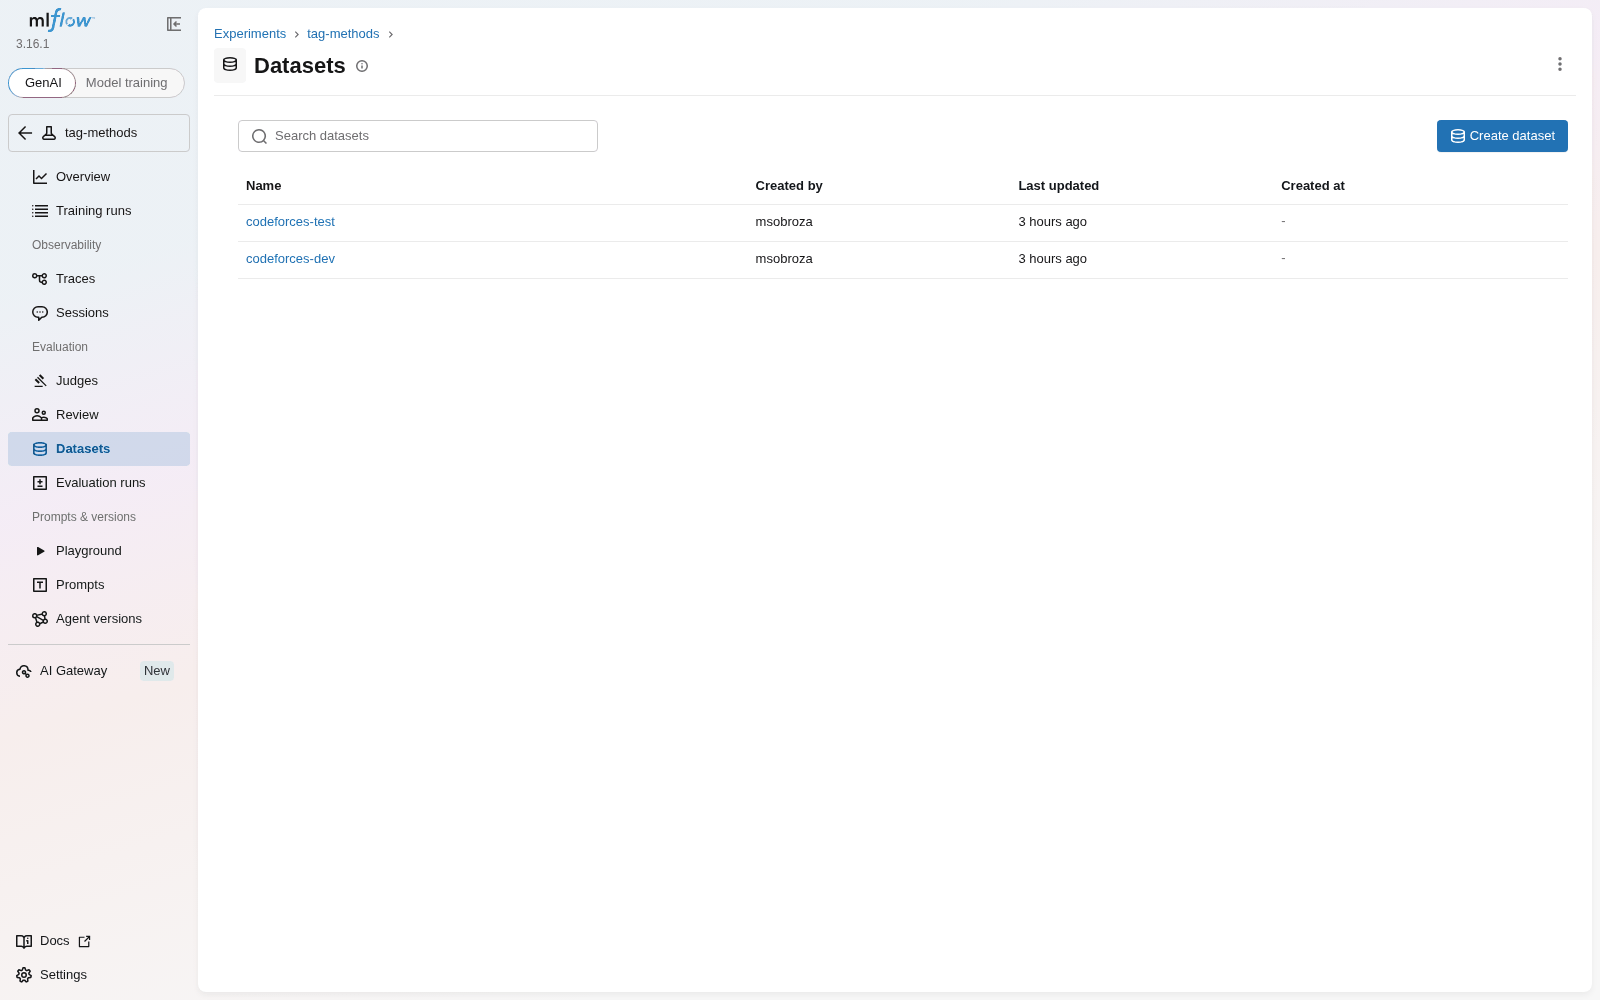

In [24]:
Image(filename=MLFLOW_SCREENS_DIR / "01_datasets.png", width=960)

**2. The dev records.** `codeforces-dev` holds 3,988 records, one per dev problem. A
record's inputs are its `sample_id`, its statement fields and its solution; its expectations are
its true `tags` and `focus_tags`; its tags give its part, its fold and its near-duplicate group.

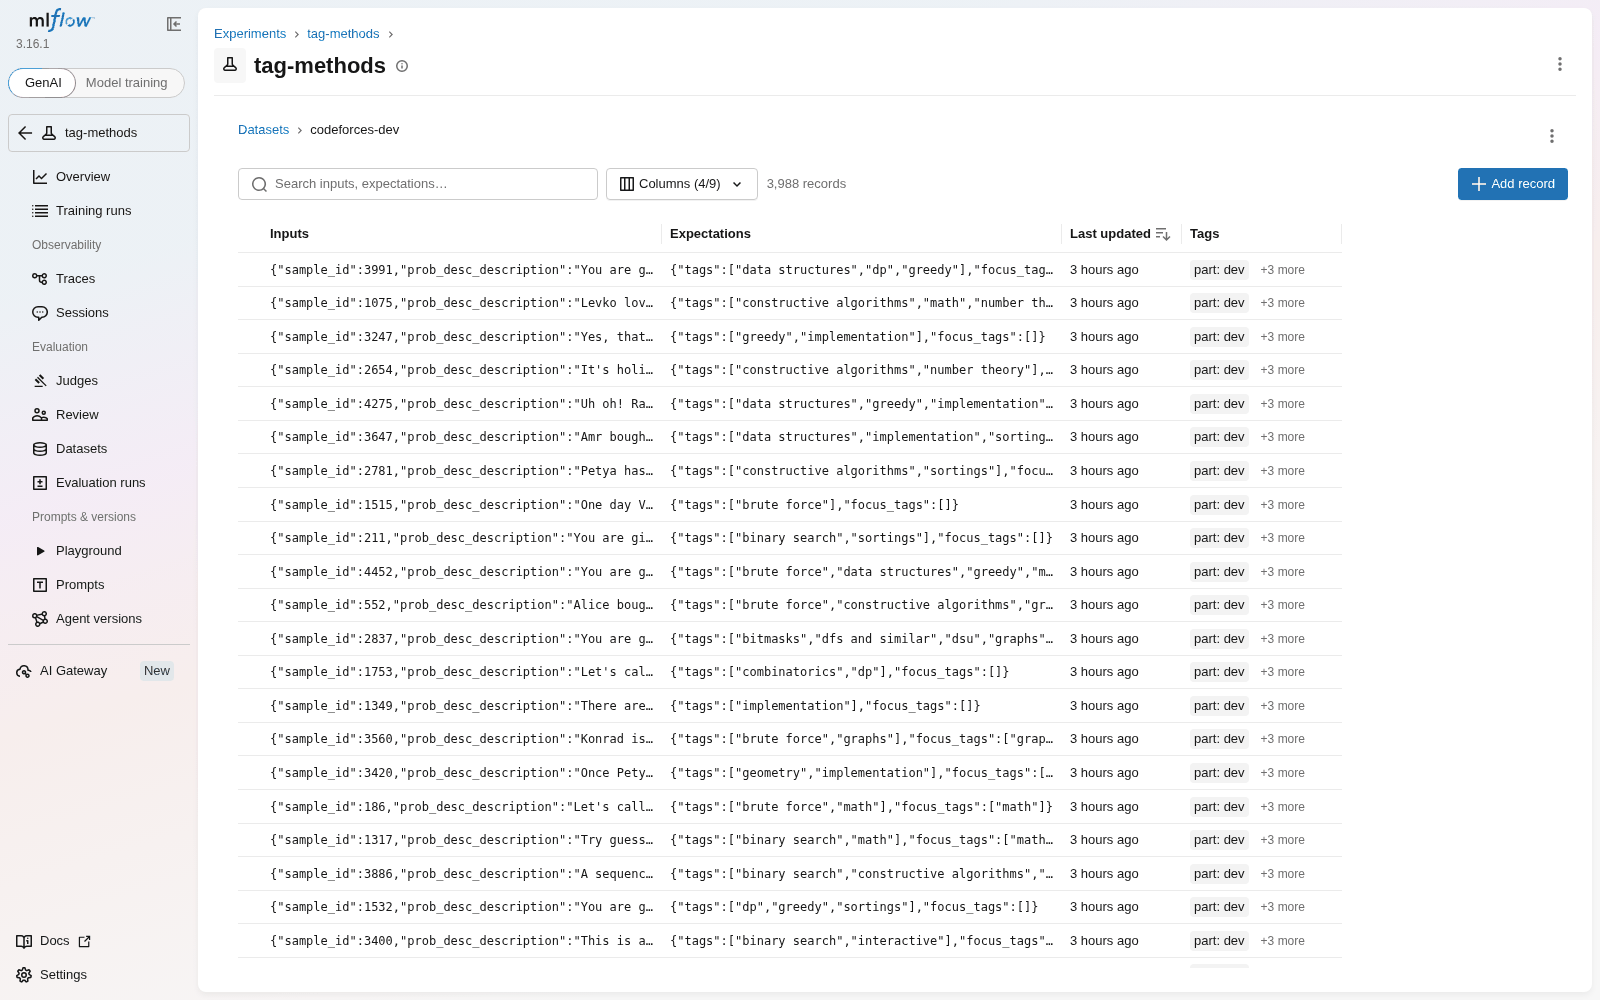

In [25]:
Image(filename=MLFLOW_SCREENS_DIR / "02_dataset_records.png", width=960)

**3. One record.** A click on a record opens its drawer: dev problem 0, the one whose
request section 1 shows. The drawer shows the inputs as raw JSON in an editor, with the solution
in a `python` fence. Nothing was edited: `tracking datasets` refuses a dataset that differs from
the dataset and the frozen split.

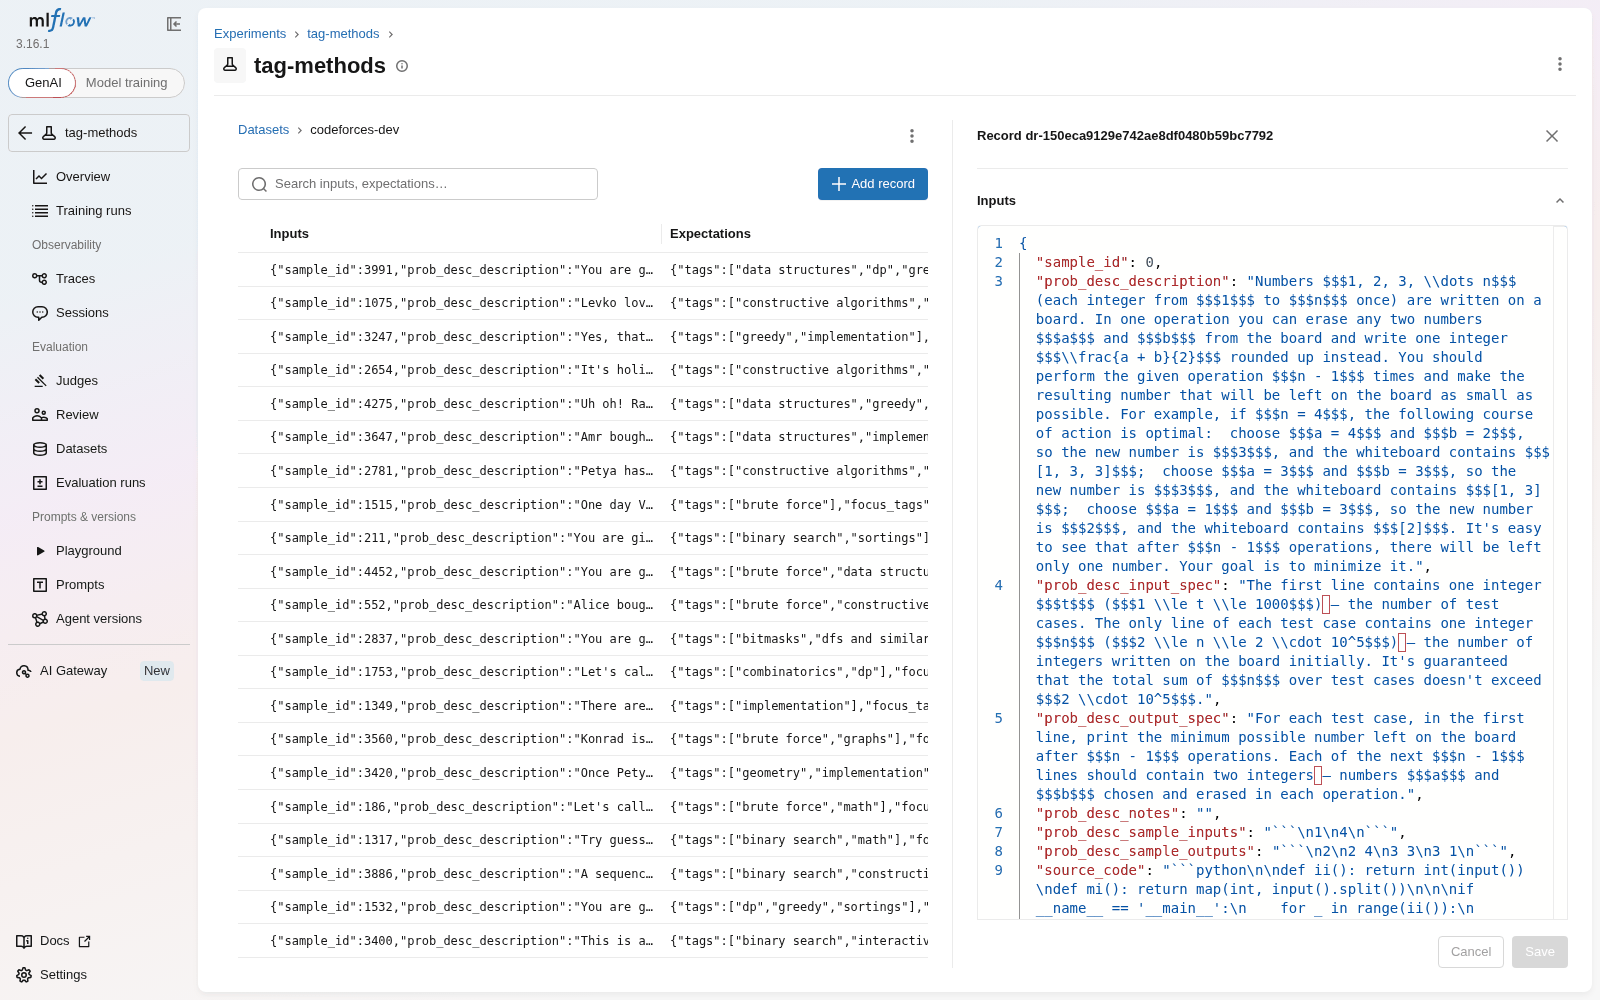

In [26]:
Image(filename=MLFLOW_SCREENS_DIR / "03_record_drawer.png", width=960)

**4. The evaluation runs.** Experiments > `tag-methods` > Evaluation runs lists the runs of
both parts, so the screenshot types `tags.part = 'dev'` in the search box: the six dev runs remain,
one per method (the Run Name column cuts their names), `descode2tag-json`'s selected. Each scorer's
mean over the dev problems is a column: `focus_exact_match/mean`, `focus_f1/mean`,
`correct_<tag>/mean` and `all_tags_jaccard/mean`, which is empty for `label_prior` and `tfidf`,
since they predict focus tags only. These are per-problem means. A run's dataset-level metrics
(`macro_f1`, `micro_f1`, the per-tag F1) come from `evaluate()` on the same frozen predictions, so
they are the scores of section 4.

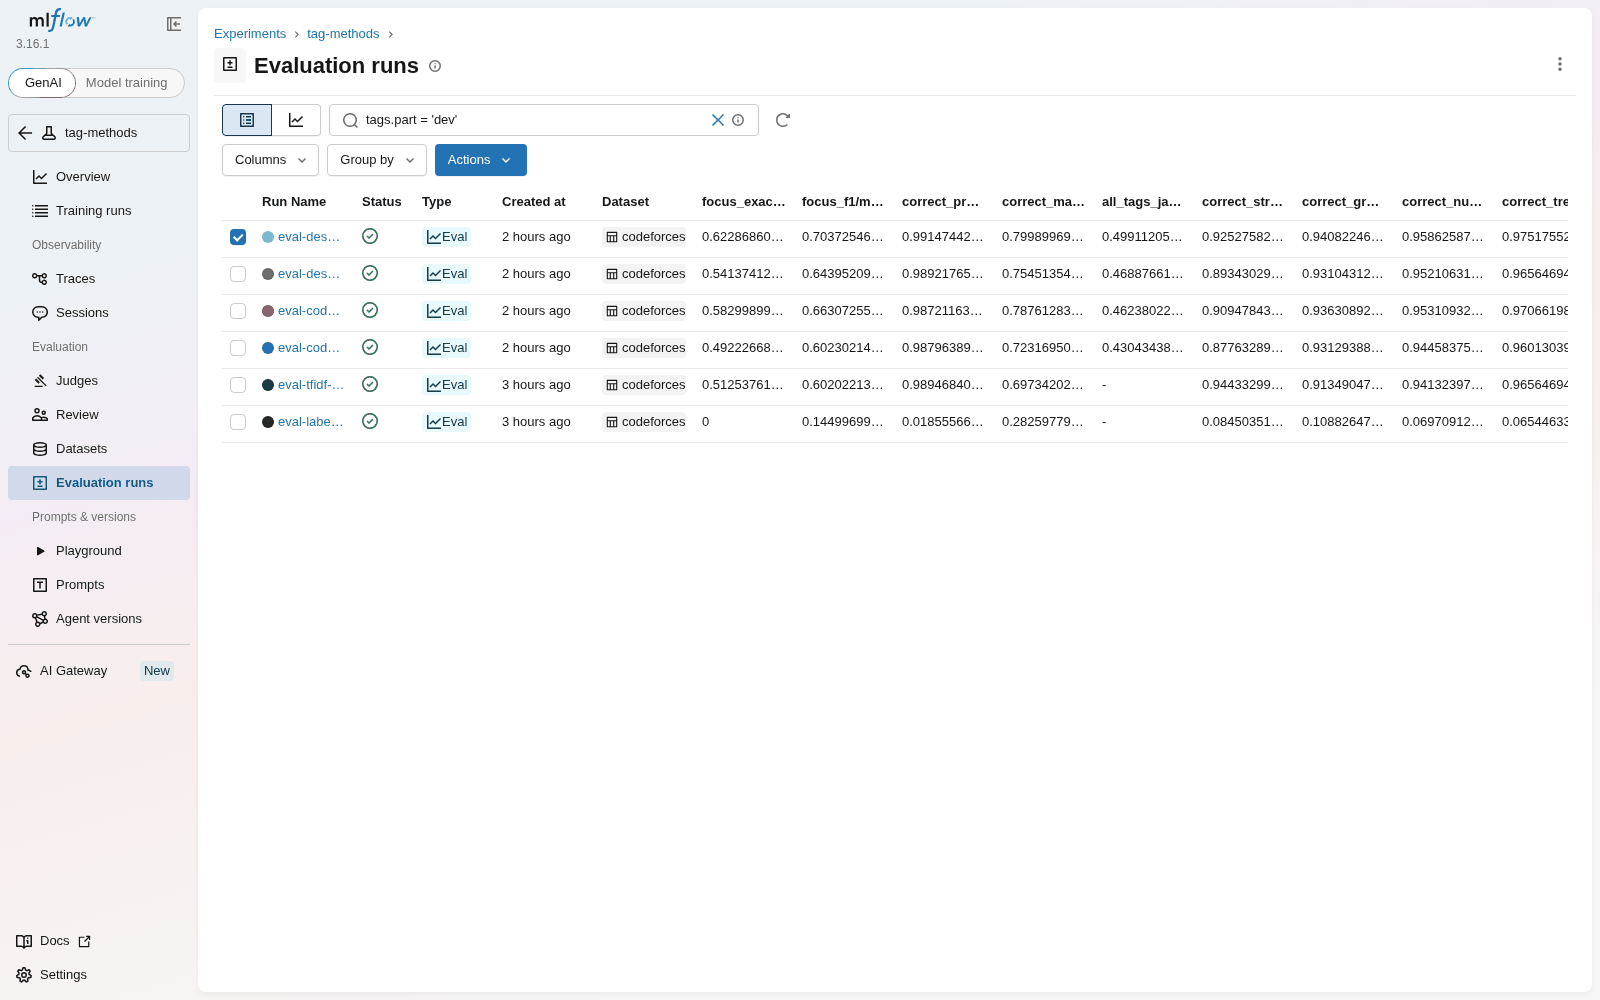

In [27]:
Image(filename=MLFLOW_SCREENS_DIR / "04_evaluation_runs.png", width=960)

**5. The same runs as charts.** The chart view of the same page draws one bar chart per
scorer mean, with one bar per dev run. `descode2tag-json` is first on the two in view,
`focus_exact_match` (0.62) and `focus_f1` (0.70); `tfidf` has 0.51 and 0.60, and `label_prior`, the
floor, 0.00 and 0.14.

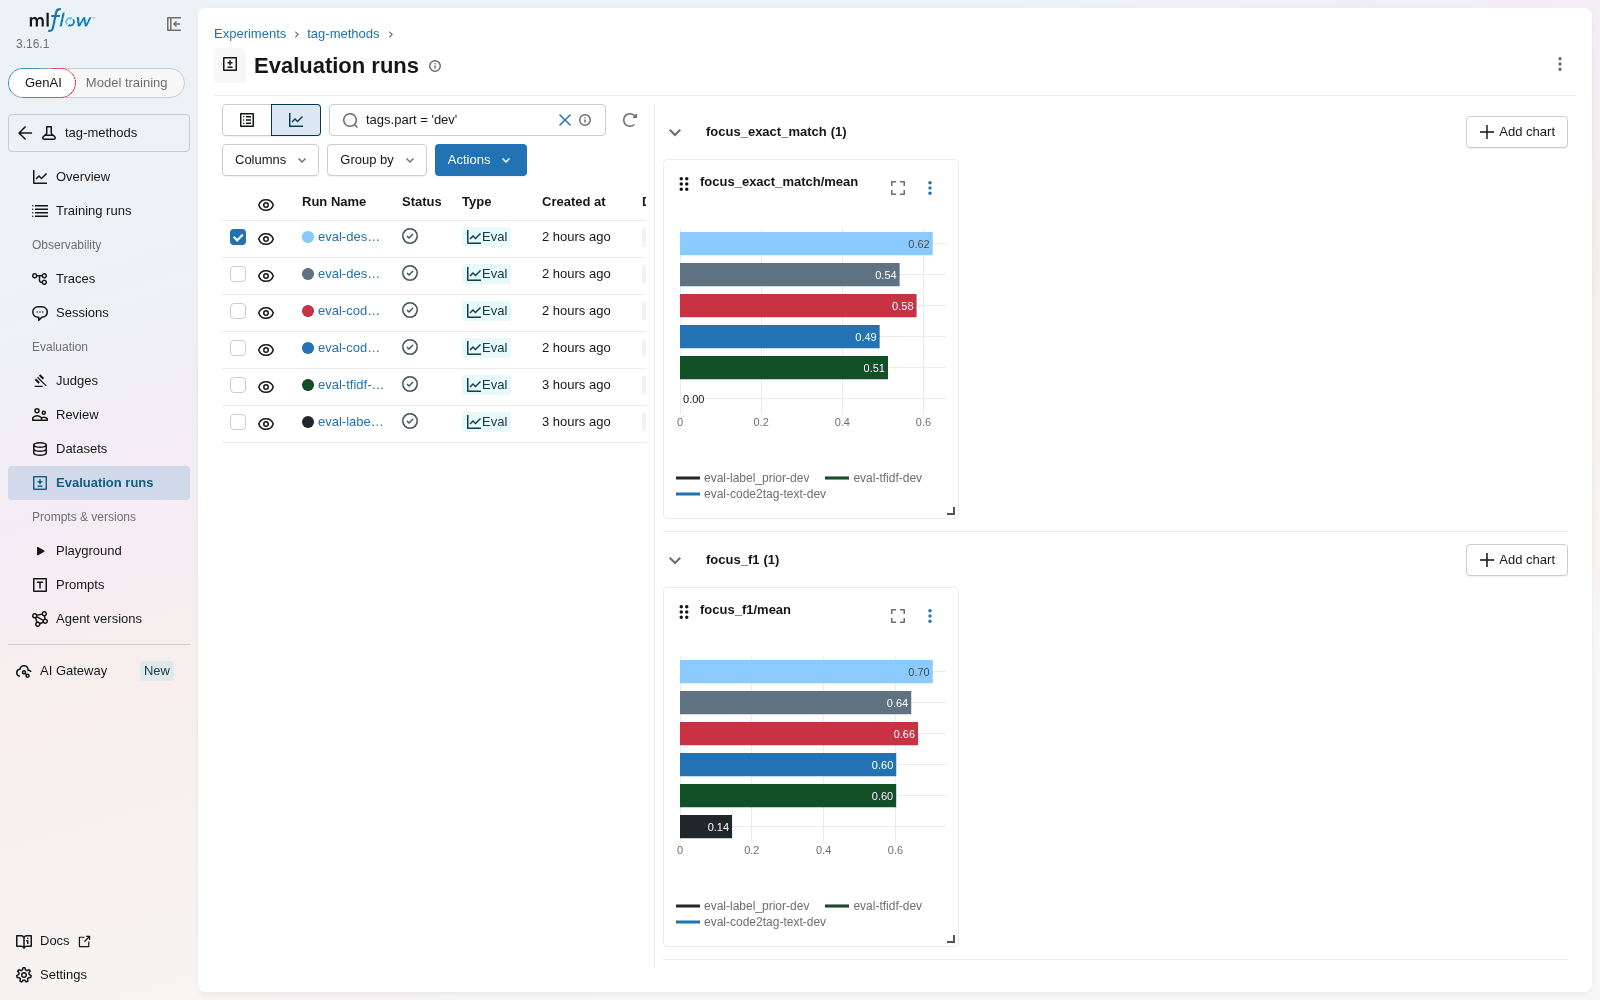

In [28]:
Image(filename=MLFLOW_SCREENS_DIR / "05_evaluation_runs_charts.png", width=960)

**6. One run's problems.** Evaluation runs > `eval-descode2tag-json-dev` > Traces has a row
per dev problem: its request (the inputs), the response (the predicted tags, and the `vocabulary`
they were chosen from), its two expectations, a column per feedback (two of the 11 are shown:
`all_tags_jaccard`, 0.5 on average, and `correct_games`, true for 99%), its tokens and its
execution time. That time, a few milliseconds, is the lookup's, not the model's: the call's own
latency is the trace's `recorded_latency_s`. The table loads 100 traces at a time (`100 of 3988`).

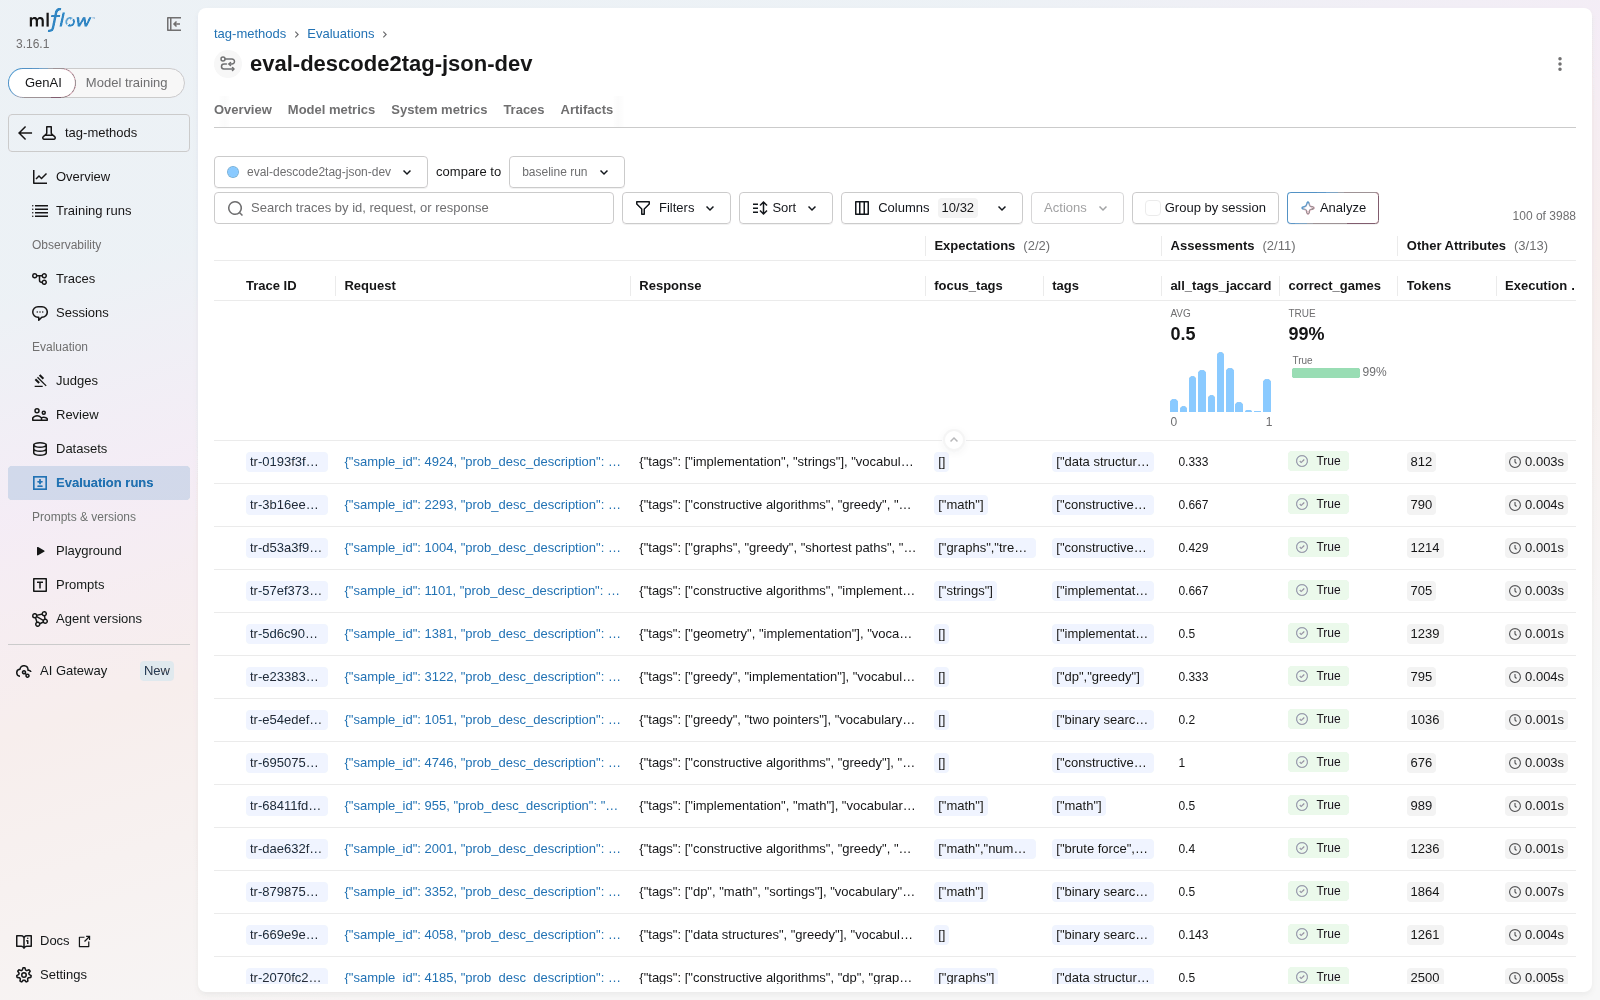

In [29]:
Image(filename=MLFLOW_SCREENS_DIR / "06_run_traces.png", width=960)

**7. One problem, one trace.** A click on a row opens the trace of problem 0: its inputs,
with the statement and the solution rendered (the solution as code), its output, `constructive
algorithms` and `greedy`, and its assessments, 11 feedbacks and 2 expectations. The expectation
`focus_tags` is `["math"]`, which `descode2tag-json` missed: `correct_math` is False, `focus_f1` 0
and `focus_exact_match` False. Its `all_tags_jaccard` is 0.4: it names 2 of the 5 true tags, and no
other. The span's header holds the recorded call, `gpt-6-luna`, 971 tokens and 0.000105 USD, which
the cell above reads from `per_problem.csv`.

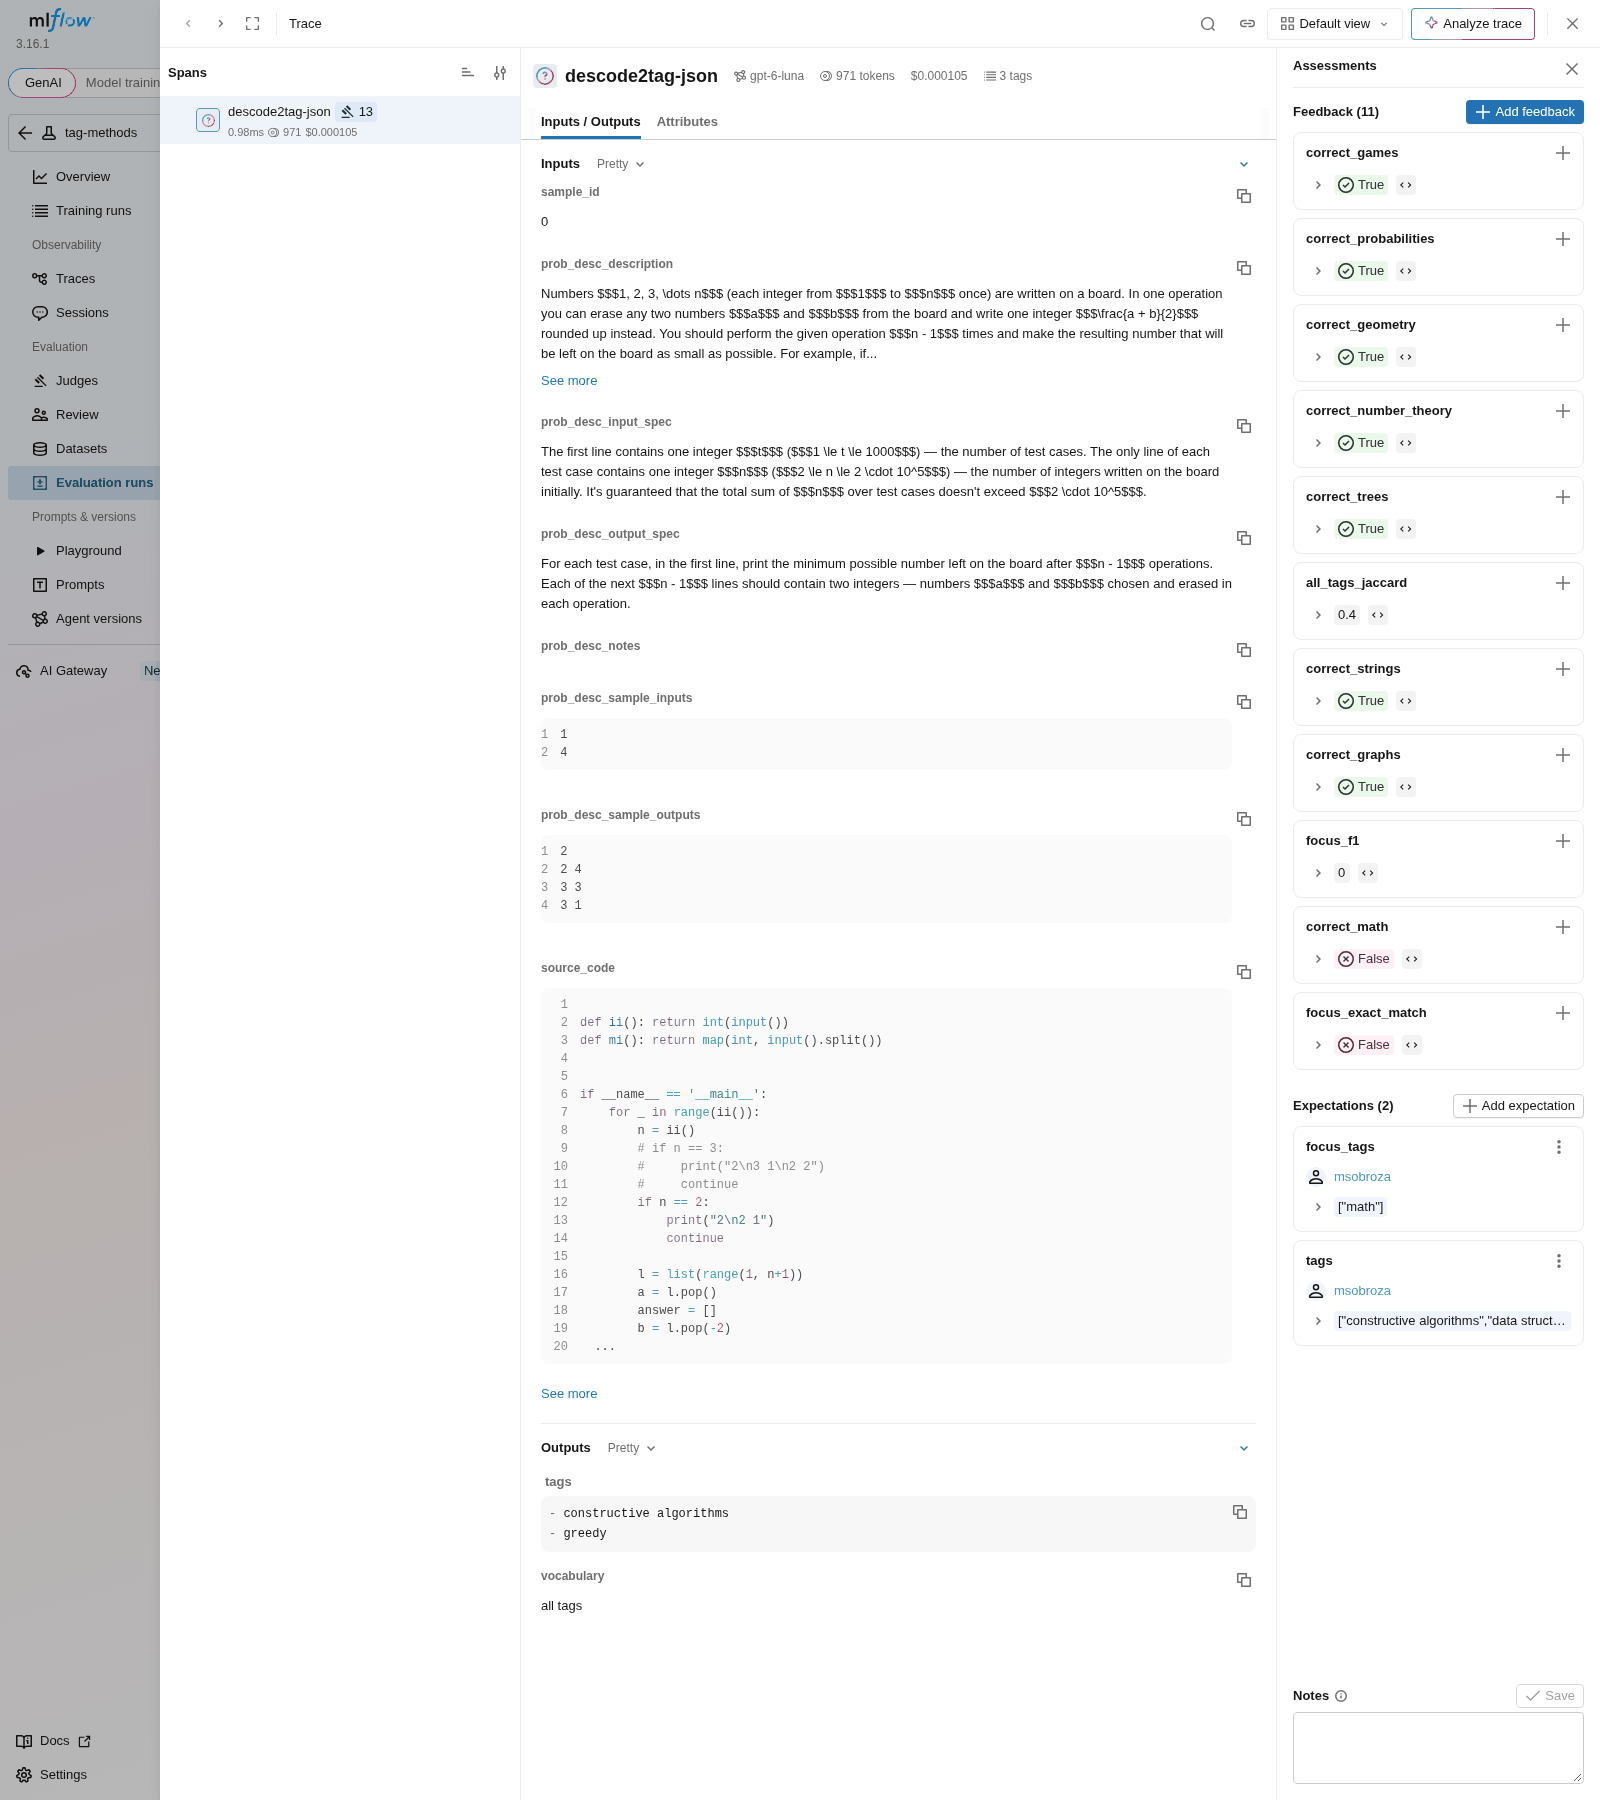

In [30]:
Image(filename=MLFLOW_SCREENS_DIR / "07_trace_drawer.png", width=960)

**8. The problems a method gets wrong.** On the same page, filtering `correct_math` on
`false` keeps the dev problems where `descode2tag-json` gets `math` wrong, here with every trace
it keeps loaded: `798 of 3988`, the count of the cell above. The screenshot shows that one filter
applies (`Filters (1)`) but not which: the filter is in the page's URL, percent-encoded
(`filter=ASSESSMENT::=::false::correct_math`), so the view is a link. The two assessment columns
on screen are `all_tags_jaccard` and `correct_games`; `correct_math` is among the hidden ones. Any
`correct_<tag>` of the 8 focus tags can be filtered the same way.

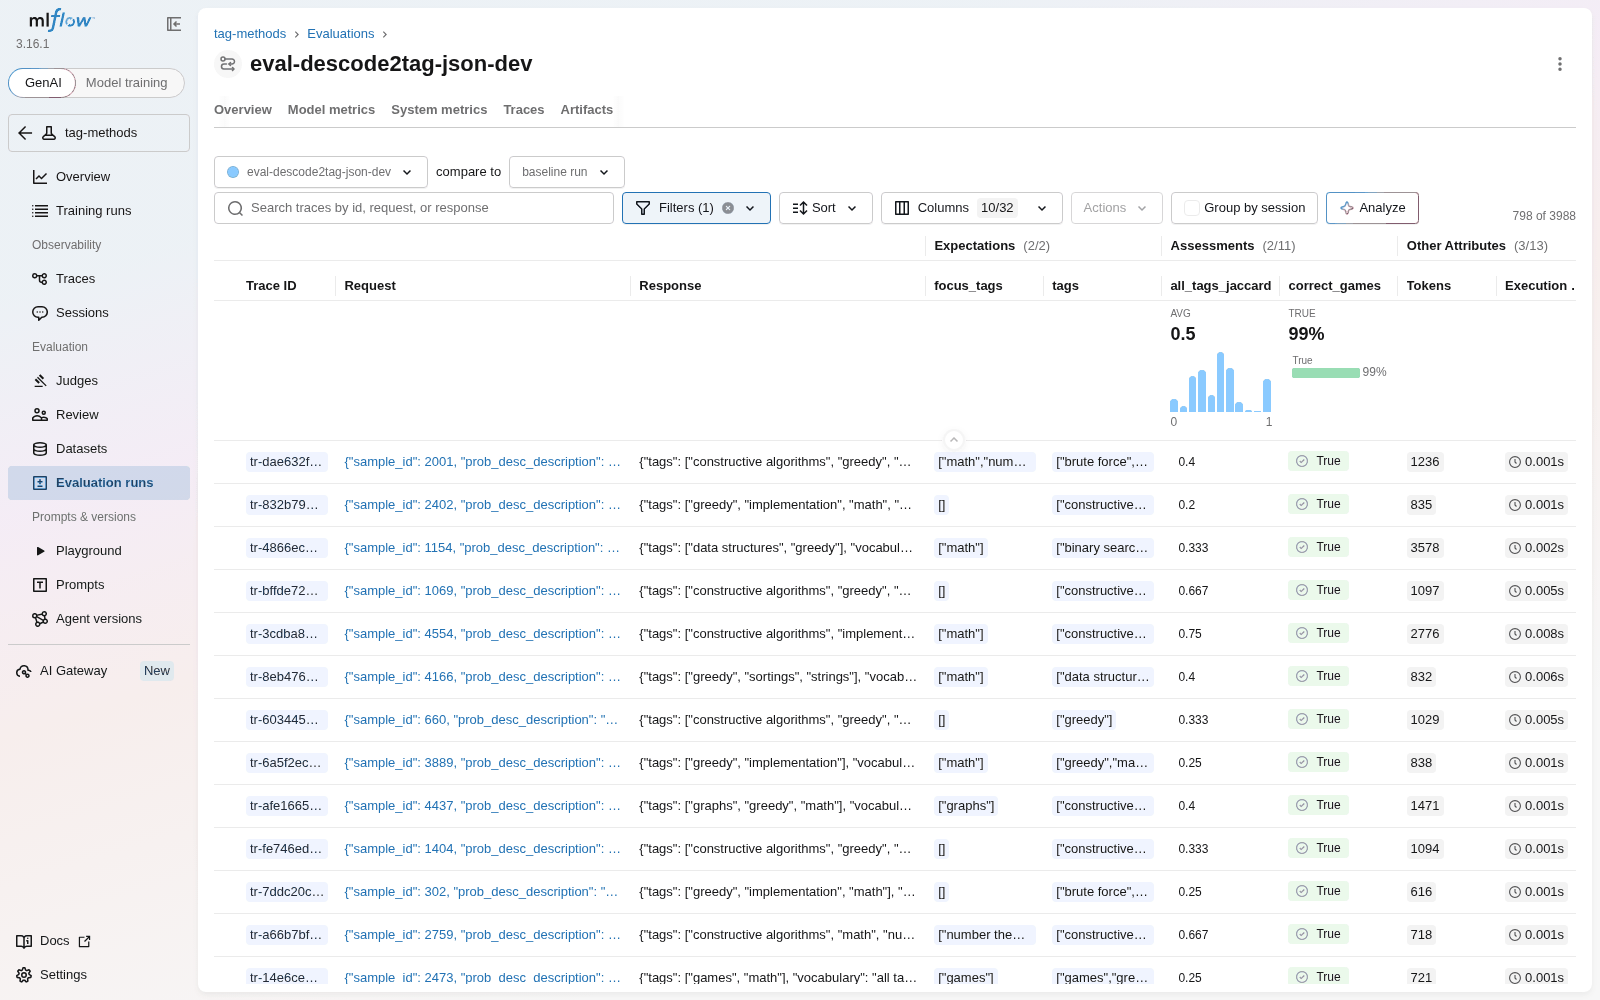

In [31]:
Image(filename=MLFLOW_SCREENS_DIR / "08_filter_false.png", width=960)

**9. Two methods on the same problems.** The compare menu of a run's Traces puts
`eval-tfidf-dev` beside `eval-descode2tag-json-dev`: two rows per problem, `tfidf`'s first, each
with its predicted tags. `tfidf` predicts over the 8 focus tags (its `vocabulary` is `focus tags`,
and its `all_tags_jaccard` and tokens are `null`: it makes no call). The compare view loads 1,000
problems at a time (`1000 of 3988`). It is the comparison of section 7, one problem at a time.

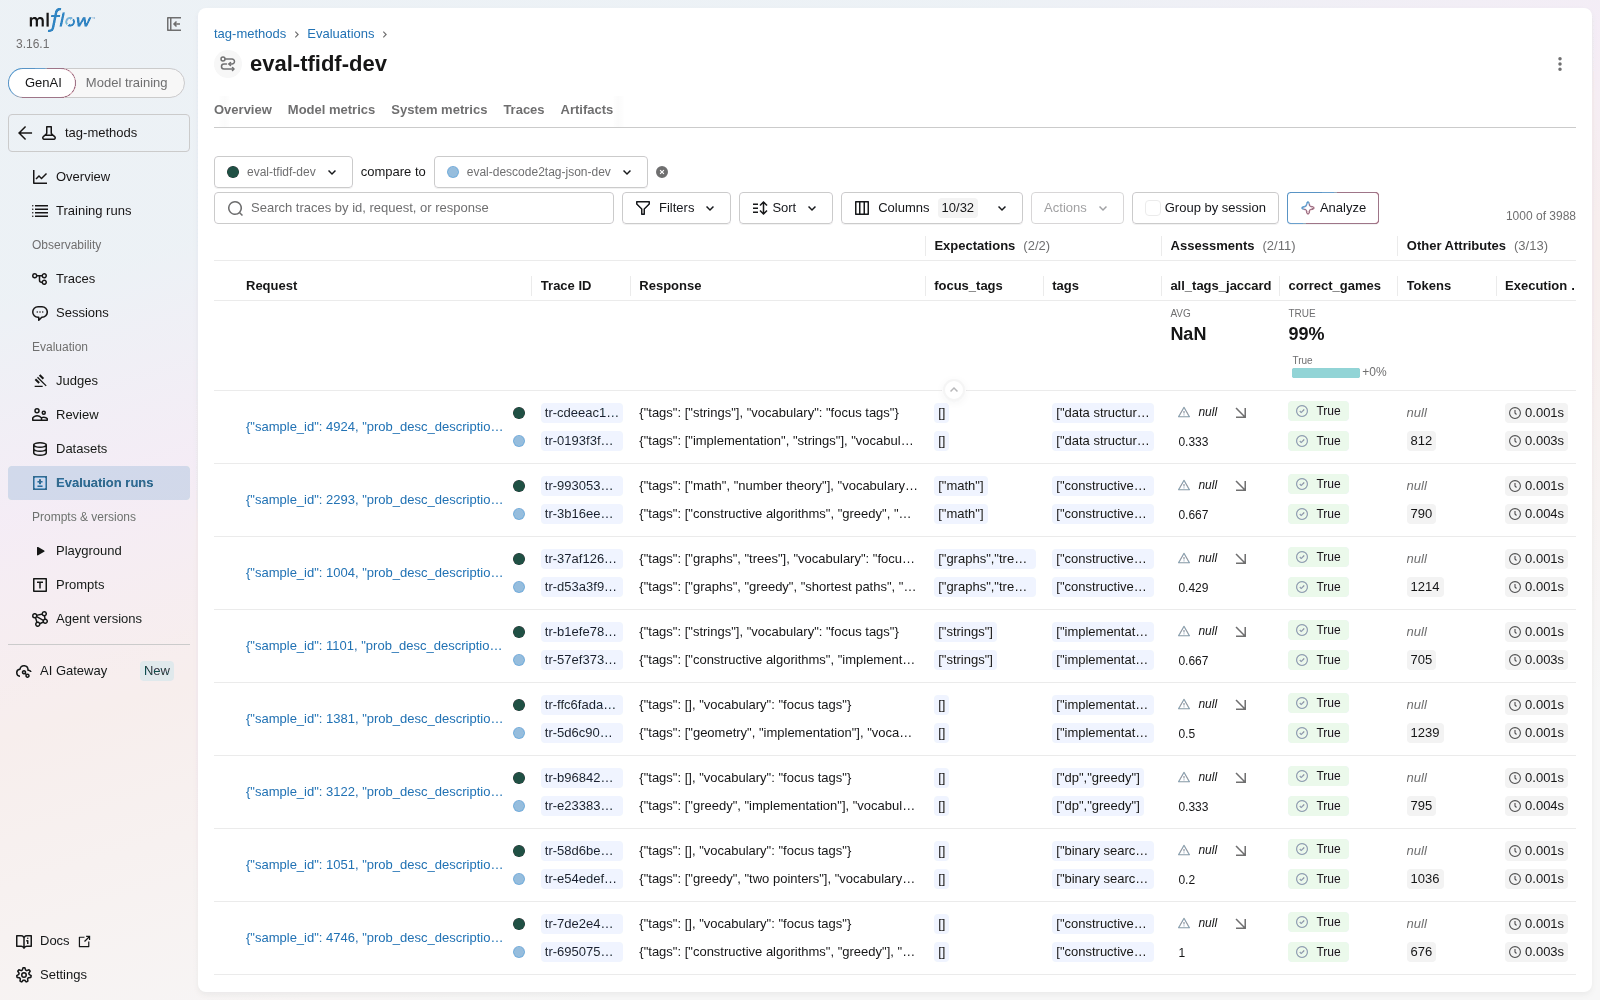

In [32]:
Image(filename=MLFLOW_SCREENS_DIR / "09_compare.png", width=960)

**10. Tokens and cost.** Experiments > `tag-methods` > Overview > Usage, over a custom
window from the first dev run's start to the last one's end, in whole minutes. It counts the
23,928 dev traces (6 methods, 3,988 problems each), 14.52M tokens (14.27M input, 249.73K output)
and a Total Cost of 1.552221 USD: the dev calls of the four zero-shot methods, as the cell above
sums them (`label_prior` and `tfidf` make no call). The cost charts split by model or provider
only, and all four methods were served by `gpt-6-luna`: they show one series and do not tell the
methods apart. Screenshot 11 shows each trace's cost beside its run name, and the cell above
prints each method's dev cost, which `tracking evaluate` matched to its run's traces. The latency,
1.78 ms, is the lookup's.

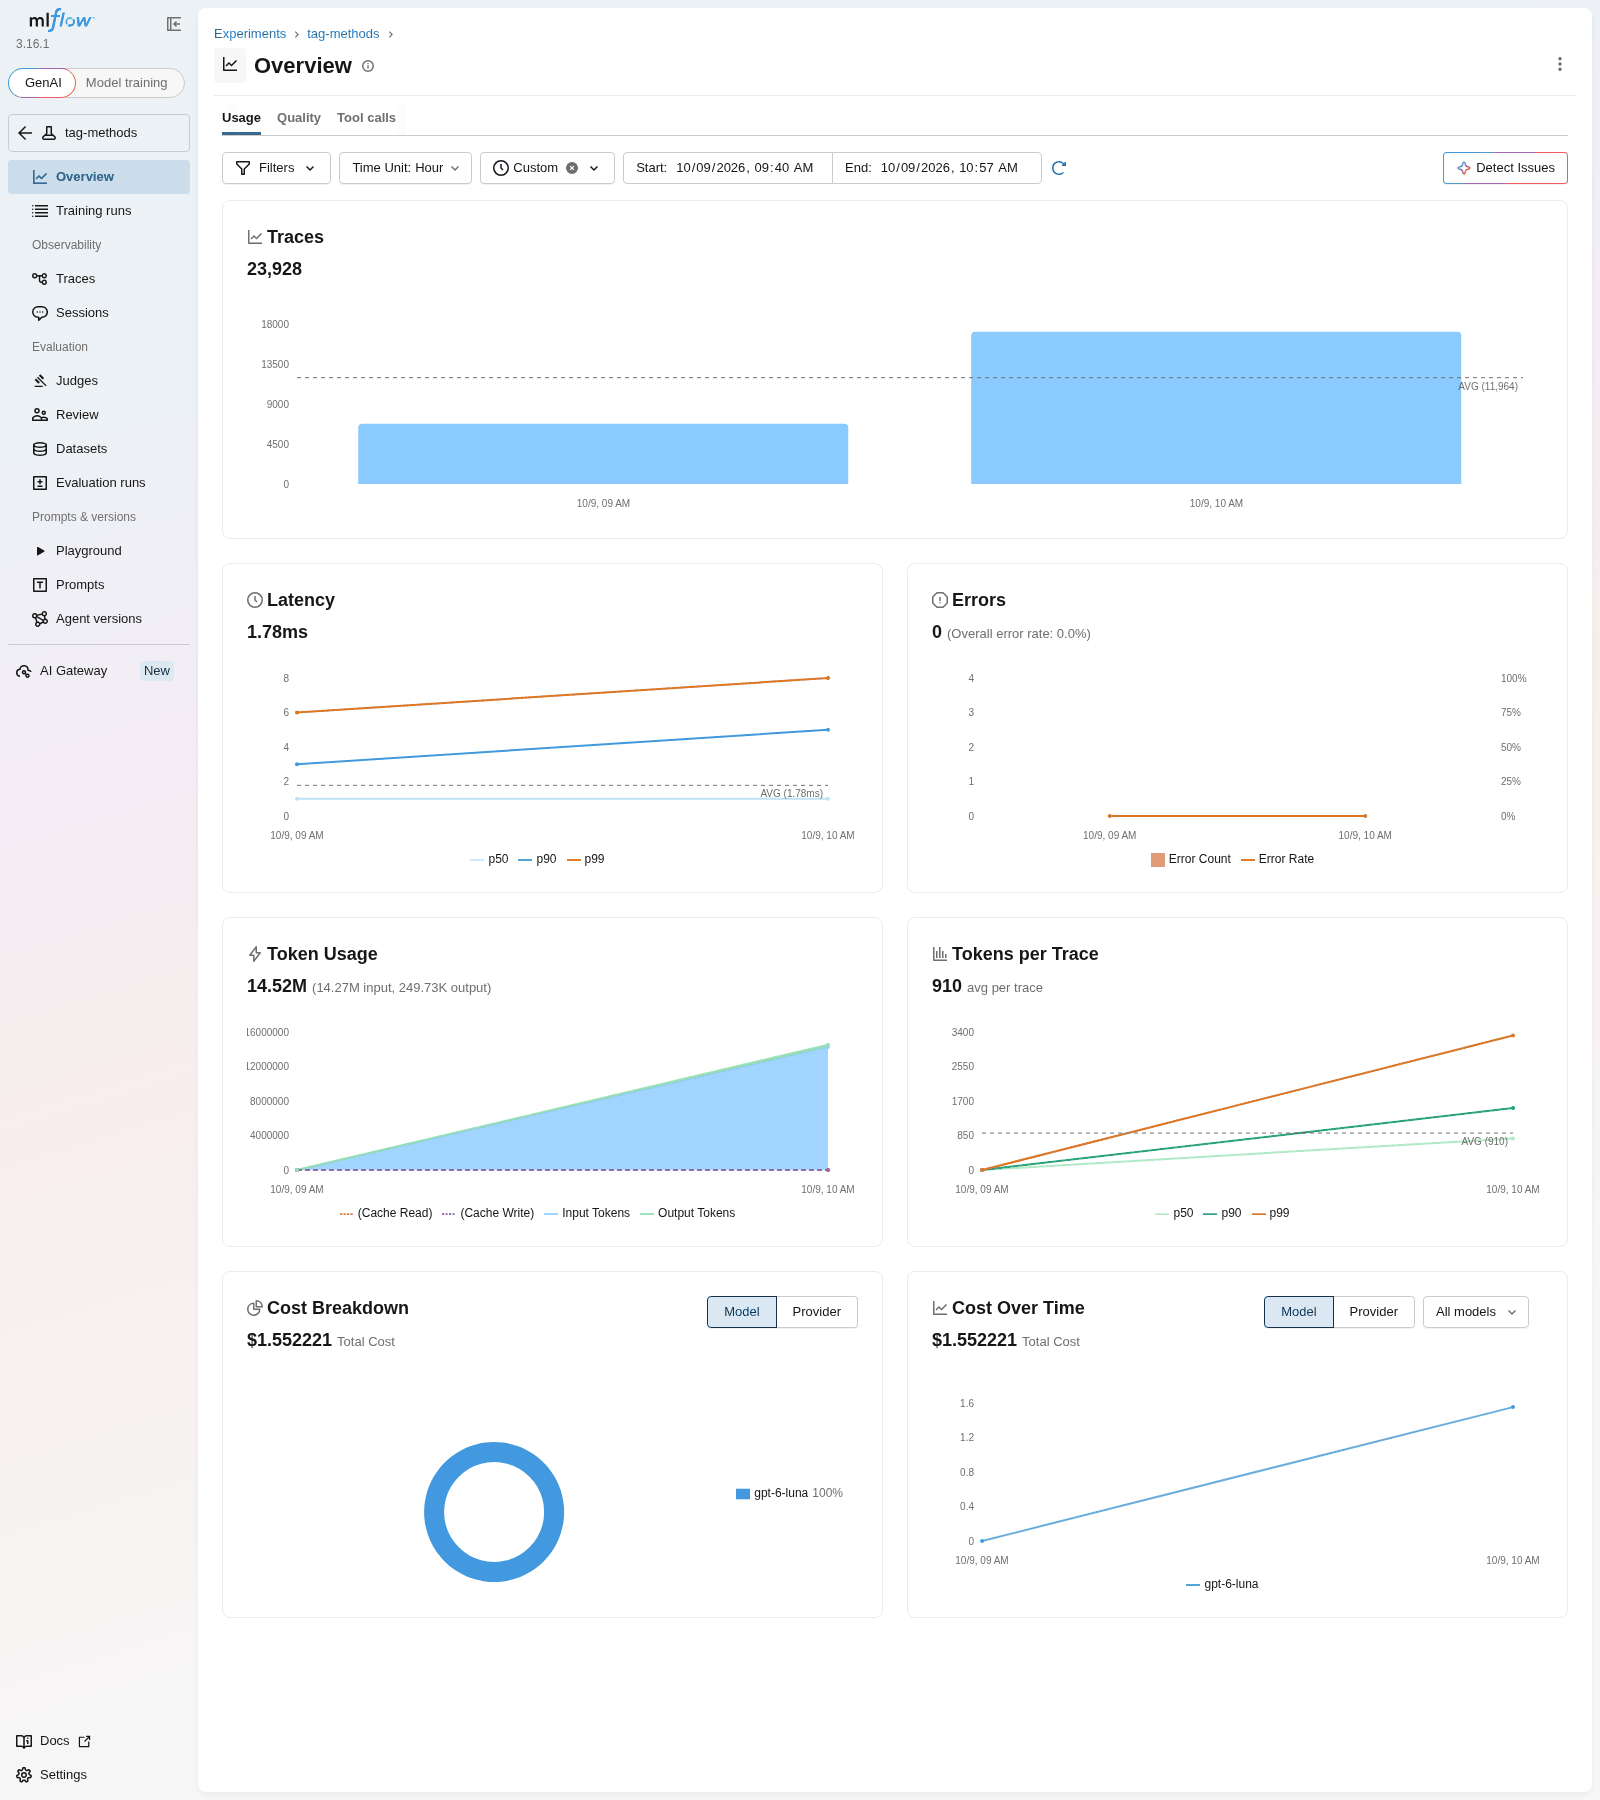

In [33]:
Image(filename=MLFLOW_SCREENS_DIR / "10_overview_usage.png", width=960)

**11. Cost per problem.** Experiments > `tag-methods` > Traces, over the same window, with
the Run name and Cost columns turned on (Display > Columns) and the assessment columns hidden; the
page is 2,000 px wide so that the columns fit. Each row is a trace, here those of
`descode2tag-json`, the last dev run made, with its recorded cost in USD. A run's costs sum to its
`per_problem.csv`'s, which `tracking evaluate` checks to a relative 1e-9 for the four zero-shot
runs: 0.530754 USD for `descode2tag-json`, as the cell above prints. This is the only page with a
Cost column; a run's own Traces tab has Tokens only.

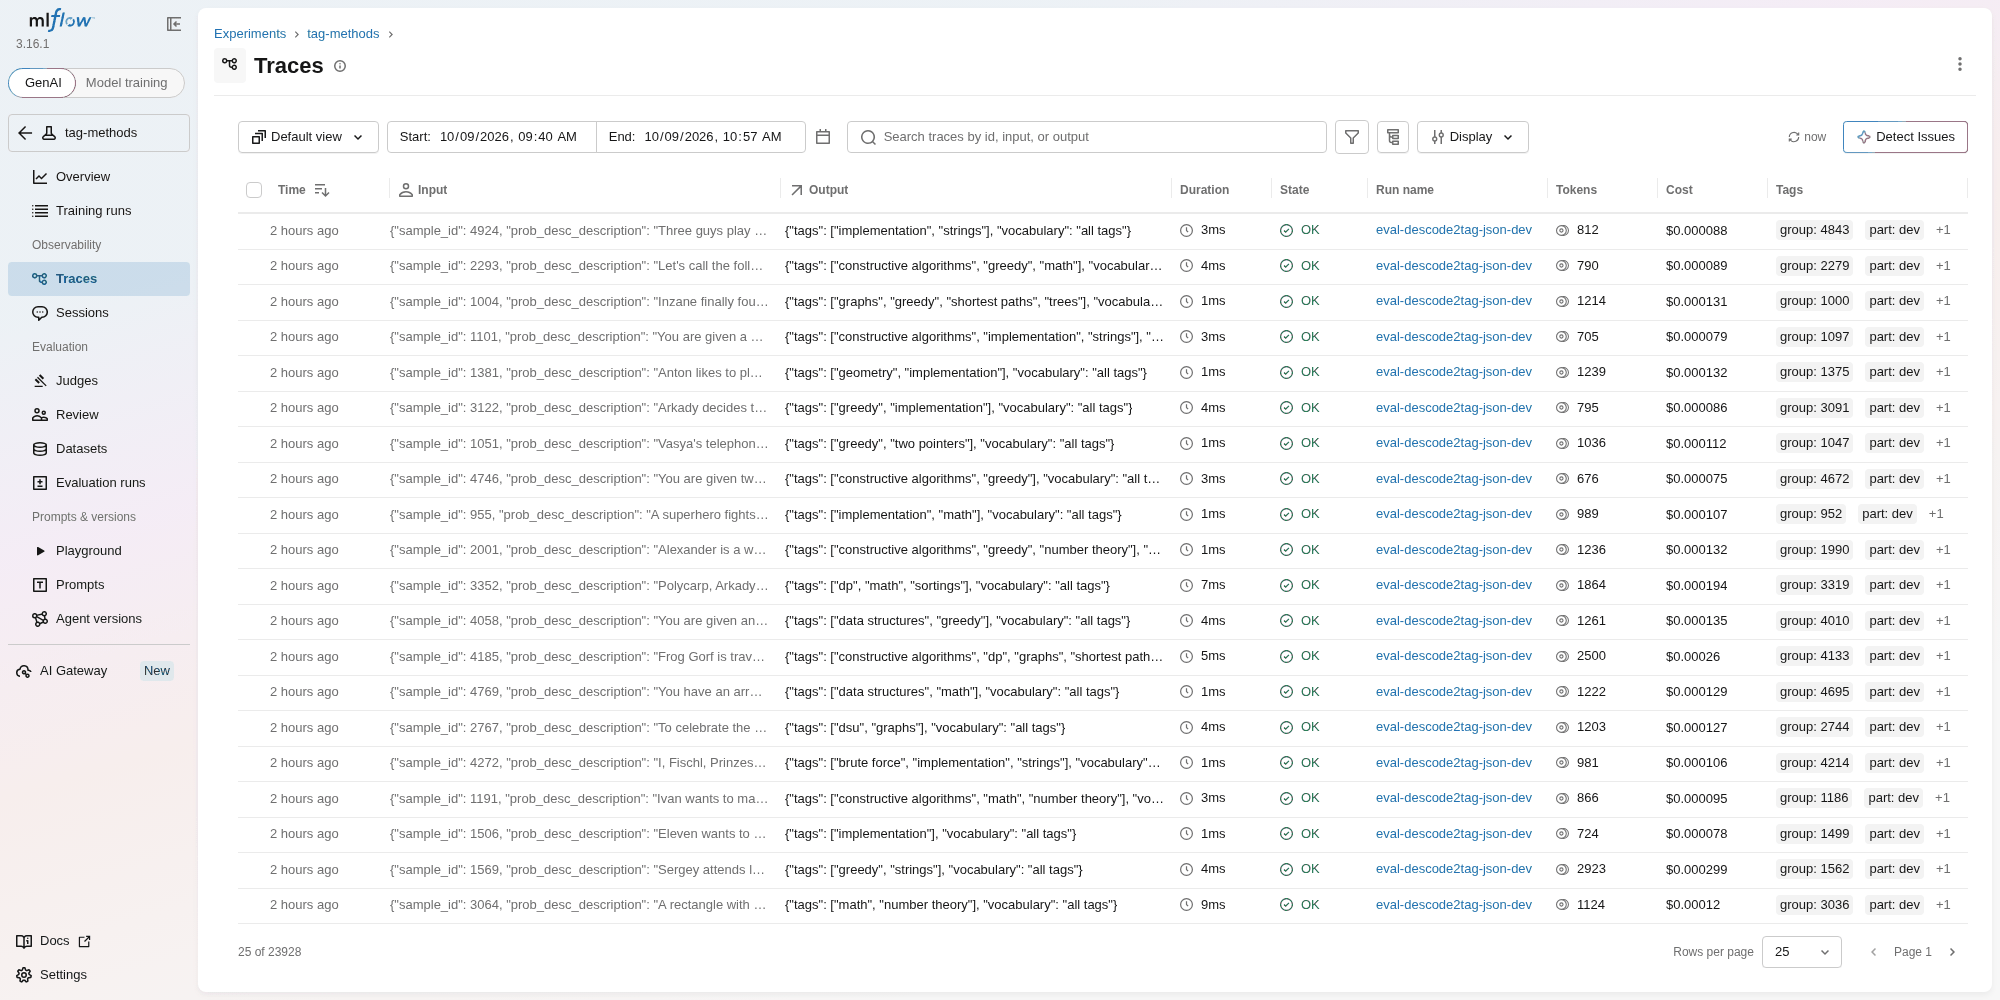

In [34]:
Image(filename=MLFLOW_SCREENS_DIR / "11_traces_cost.png", width=960)

**12. The prompts.** Prompts > `descode2tag` lists its versions: version 1 `@ text` and
version 2 `@ json` (the aliases mirror the frozen runs and gate nothing). A version holds its
commit message, a `content_sha256` tag that fingerprints its prompt, the request settings it was
frozen with and the template, shown here as Markdown; version 2 adds the strict JSON schema,
Structured output. Each method's run record pins one version (`prompts:/descode2tag/2` for
`descode2tag-json`), the one section 1 shows.

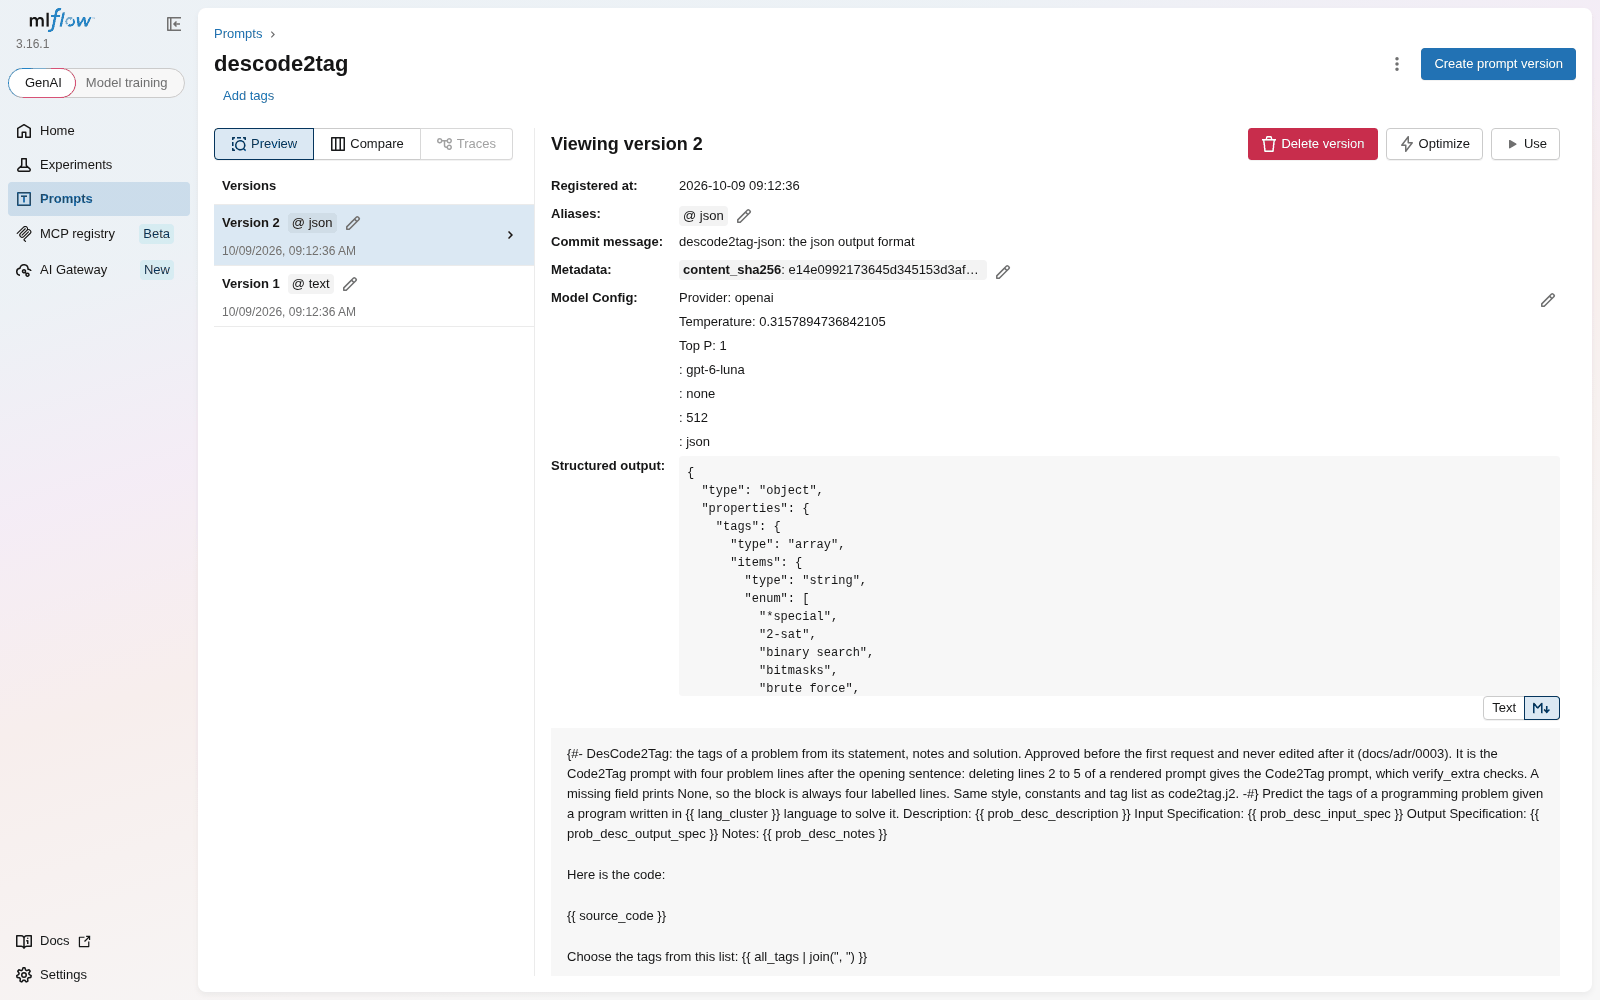

In [35]:
Image(filename=MLFLOW_SCREENS_DIR / "12_prompt_versions.png", width=960)

**13. What changes between the versions.** Compare puts version 1 beside version 2. The two
templates are the same text, so the comparison highlights nothing in them; the versions differ
only in the response format: version 2 sets the format to `json` and adds the schema. This is the
format ablation of section 5, which changes nothing else.

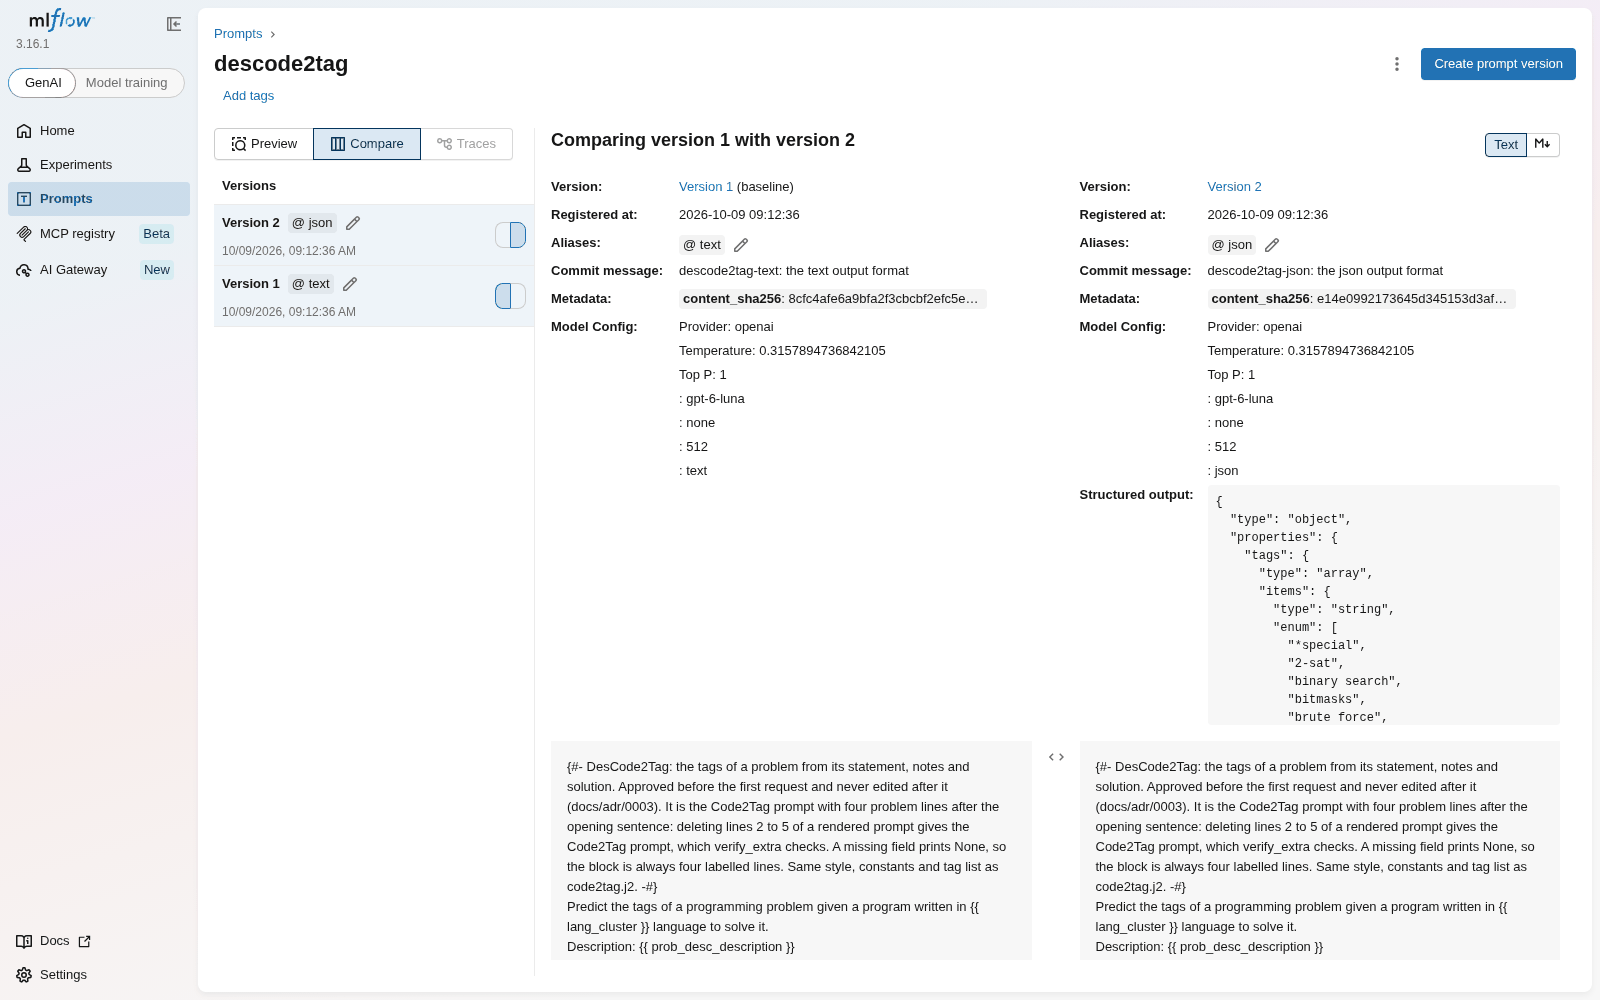

In [36]:
Image(filename=MLFLOW_SCREENS_DIR / "13_prompt_compare.png", width=960)

## 10. Takeaways and next steps

**Results**
- **Against the paper** (section 3). With `gpt-6-luna`, the paper's free-text setup scores an
  all-tag macro F1 of 46.8 from the solution and 49.8 from the statement and the solution on
  dev (48.3 and 51.8 on test), against the paper's 29.45 and 33.73 with
  `gpt-3.5-turbo-0301`. On dev the problem text helps by +3.0, against the paper's +4.28
  (+3.5 on test, reported only): the direction of the paper's gain is reproduced on dev, not
  its numbers, which come from other tags, problems, solutions and a model three years older.
- **Against TF-IDF** (section 4). On the focus tags, `descode2tag-json` scores 0.732 on dev, a
  paired +0.069 [+0.051, +0.087] over `tfidf`, and `descode2tag-text` +0.043
  [+0.025, +0.061]; from the solution alone, the Code2Tag methods are on par with `tfidf`. On
  test, scored once and side by side: 0.741 and 0.721 against `tfidf`'s 0.689.
- **Per tag** (sections 4 and 7), the LLM is better on `graphs`, `number theory` and `math`, and
  `tfidf` on `strings`, and on `games` against Code2Tag. Free text over-predicts: 3.4 to 3.5
  tags per answer against 2.8 true labels, with a high recall and a low precision (section 2).
- **Free text against structured output** (section 5), concluded on dev before any test
  request: `json` is better for DesCode2Tag (+0.026 [+0.014, +0.037]), and no difference is
  detected for Code2Tag (+0.009 [-0.004, +0.023]). It costs 147 more input tokens per request
  and longer answers; no answer failed in either format.
- **Contamination** (section 6). Without the 50 self-identifying solutions of dev, the largest
  move of a macro F1 is 0.001 (0.003 on test, without its 16, reported only), and every
  problem predates the model's cutoff, so nothing here tells recall from inference: the
  zero-shot scores may overstate what the model would score on problems it has never seen.
- **Fast enough and cheap** (section 8): about 1 s per problem, at most 4.4 s, under the 10 s
  budget; 0.06 to 0.13 USD per 1,000 problems; 1.94 USD for the whole study.
- **Every problem is in MLflow** (section 9): the frozen predictions of the six methods are
  logged per problem, 29,892 traces, each with its true tags, its predicted tags, whether each
  focus tag is right and, for a zero-shot method, its tokens and cost. In the dev screenshots,
  `descode2tag-json` gets `math` wrong on 798 problems, one filter away, and the dev calls of
  the four zero-shot methods cost 1.552221 USD together.

**For the slides**
- **The protocol.** Prompts written once and approved before the first request; every answer
  frozen in a committed, append-only file; dev asked, and the format comparison concluded,
  before test; every number derived again offline from the answers files
  (`python -m codeforces_tags.llm verify`).
- **The deviations from the paper** (section 1): our prompts (the paper's are unpublished), the
  statement and the notes in DesCode2Tag, 37 tags listed, `gpt-6-luna` at effort `none`, `None`
  for a missing field, no truncation, one solution per problem, our split.
- **Eligibility.** A zero-shot method is a fixed reference model whose dev predictions are
  honest, and all four are under the latency budget, so by the rule of
  [ADR 0004](../docs/adr/0004-tagging-method-framework.md) they are eligible for the CLI, which
  is chosen on dev focus macro F1 among all the frozen methods. Of the six compared here,
  `descode2tag-json` has the best. Serving it takes a network call, an API key and about
  0.13 USD per 1,000 problems, and its answers cannot be asked again identically: the API has
  no seed.

**Next steps** (none was tried here)
- **Few-shot prompting**: a fitted prompted method, its examples drawn from the other dev folds
  (`cross_requests`), so that its dev answers stay out of fold.
- **Reasoning effort**: the same prompts at effort `low` or `medium`, as new methods under new
  prompt names: slower and costlier, it varies the one setting fixed at `none` here.
- **Combining methods**: `tfidf` and the LLM are right on different problems (section 7). A
  stack over both, cross-fitted on dev, or a per-tag choice between them made on dev, could
  use it.
- **Eliciting a confidence**: a score per tag (the answer's log-probabilities, or a stated
  confidence) would let each tag get a cross-fitted threshold, as `tfidf`'s scores do, and
  trade free text's recall for precision.

The last cell checks that the notebook imported neither mlflow nor openai.

In [37]:
assert "mlflow" not in sys.modules, "the notebook imported mlflow"
assert "openai" not in sys.modules, "the notebook imported openai"
assert "playwright" not in sys.modules, "the notebook imported playwright"
print("imported neither mlflow nor openai")

imported neither mlflow nor openai
